In [2]:
import pandas as pd
import numpy as np

In [3]:
data_path = "/home/maryam/Downloads/EMSCAD_Project/data/raw/DataSet.csv"

df = pd.read_csv(data_path)

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (17880, 18)


In [5]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']


In [6]:
print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,in_balanced_dataset
0,Marketing Intern,"US, NY, New York",Marketing,NaN,"<h3>We're Food52, and we've created a groundbr...","<p>Food52, a fast-growing, James Beard Award-w...",<ul>\r\n<li>Experience with content management...,NaN,f,t,f,Other,Internship,NaN,NaN,Marketing,f,f
1,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"<h3>90 Seconds, the worlds Cloud Video Product...",<p>Organised - Focused - Vibrant - Awesome!<br...,<p><b>What we expect from you:</b></p>\r\n<p>Y...,<h3><b>What you will get from us</b></h3>\r\n<...,f,t,f,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,f,f
2,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,<h3></h3>\r\n<p>Valor Services provides Workfo...,"<p>Our client, located in Houston, is actively...",<ul>\r\n<li>Implement pre-commissioning and co...,NaN,f,t,f,NaN,NaN,NaN,NaN,NaN,f,f
3,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,<p>Our passion for improving quality of life t...,<p><b>THE COMPANY: ESRI – Environmental System...,<ul>\r\n<li>\r\n<b>EDUCATION: </b>Bachelor’s o...,<p>Our culture is anything but corporate—we ha...,f,t,f,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,f,f
4,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,<p>SpotSource Solutions LLC is a Global Human ...,<p><b>JOB TITLE:</b> Itemization Review Manage...,<p><b>QUALIFICATIONS:</b></p>\r\n<ul>\r\n<li>R...,<p>Full Benefits Offered</p>,f,t,t,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,f,f


In [7]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   title                17880 non-null  str  
 1   location             17534 non-null  str  
 2   department           6333 non-null   str  
 3   salary_range         2868 non-null   str  
 4   company_profile      14572 non-null  str  
 5   description          17880 non-null  str  
 6   requirements         15191 non-null  str  
 7   benefits             10684 non-null  str  
 8   telecommuting        17880 non-null  str  
 9   has_company_logo     17880 non-null  str  
 10  has_questions        17880 non-null  str  
 11  employment_type      14409 non-null  str  
 12  required_experience  10830 non-null  str  
 13  required_education   9775 non-null   str  
 14  industry             12977 non-null  str  
 15  function             11425 non-null  str  
 16  fraudulent  

In [8]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                0
requirements            2689
benefits                7196
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
in_balanced_dataset        0
dtype: int64


In [9]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
235


In [10]:
print("\nTarget Distribution:")
print(df["fraudulent"].value_counts())


Target Distribution:
fraudulent
f    17014
t      866
Name: count, dtype: int64


In [11]:

print("Rows before removing duplicates:", len(df))


df = df.drop_duplicates().reset_index(drop=True)


print("Rows after removing duplicates:", len(df))
print("Duplicates remaining:", df.duplicated().sum())

Rows before removing duplicates: 17880
Rows after removing duplicates: 17645
Duplicates remaining: 0


In [12]:
print("salary_range:")
print(df["salary_range"].value_counts(dropna=False).head(20))



salary_range:
salary_range
NaN             14813
0-0               141
40000-50000        66
30000-40000        54
45000-67000        36
25000-30000        36
30000-50000        32
80000-100000       30
35000-45000        30
70000-90000        29
50000-70000        28
55000-75000        28
50000-80000        28
60000-80000        28
30000-35000        27
40000-60000        27
40000-45000        27
25000-35000        26
50000-60000        24
45000-50000        22
Name: count, dtype: int64


In [13]:
print("\nFraud rate by salary_range:")
print(
    df.groupby("salary_range", dropna=False)["fraudulent"]
      .value_counts(normalize=True)
      .unstack(fill_value=0)
)


Fraud rate by salary_range:
fraudulent             f         t
salary_range                      
0-0             0.971631  0.028369
0-1             1.000000  0.000000
0-1000          1.000000  0.000000
0-100000        1.000000  0.000000
0-110406        1.000000  0.000000
...                  ...       ...
96000-240000    1.000000  0.000000
960000-1200000  1.000000  0.000000
962-962         1.000000  0.000000
99000-99999     1.000000  0.000000
NaN             0.957065  0.042935

[875 rows x 2 columns]


In [14]:
print("\nin_balanced_dataset:")
print(df["in_balanced_dataset"].value_counts(dropna=False))



in_balanced_dataset:
in_balanced_dataset
f    16751
t      894
Name: count, dtype: int64


In [15]:
print("\nFraudulent distribution by in_balanced_dataset:")
print(
    pd.crosstab(
        df["in_balanced_dataset"],
        df["fraudulent"],
        normalize="index")
)


Fraudulent distribution by in_balanced_dataset:
fraudulent                  f         t
in_balanced_dataset                    
f                    0.975285  0.024715
t                    0.503356  0.496644


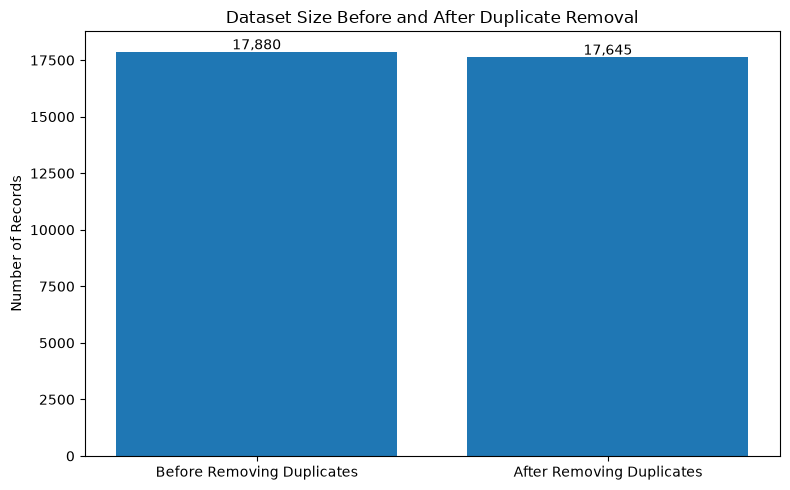

In [16]:
import matplotlib.pyplot as plt
before_duplicates = 17880
after_duplicates = len(df)

duplicate_data = {
    "Before Removing Duplicates": before_duplicates,
    "After Removing Duplicates": after_duplicates
}

plt.figure(figsize=(8, 5))
plt.bar(
    duplicate_data.keys(),
    duplicate_data.values()
)

plt.title("Dataset Size Before and After Duplicate Removal")
plt.ylabel("Number of Records")

for i, value in enumerate(duplicate_data.values()):
    plt.text(i, value + 100, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["fraudulent"])
y = df["fraudulent"].map({"f": 0, "t": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())



Training set: (14116, 17)
Testing set: (3529, 17)

Training class distribution:
fraudulent
0    13430
1      686
Name: count, dtype: int64

Testing class distribution:
fraudulent
0    3357
1     172
Name: count, dtype: int64


In [18]:
print("Current df shape:", df.shape)

print("\nCurrent columns:")
print(df.columns.tolist())

print("\nX shape:", X.shape)

Current df shape: (17645, 18)

Current columns:
['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']

X shape: (17645, 17)


In [19]:
print("Remaining exact duplicates:", df.duplicated().sum())

Remaining exact duplicates: 0


In [20]:

df = df.drop(columns=["salary_range", "in_balanced_dataset"])

print("Dataset shape:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

Dataset shape: (17645, 16)

Remaining columns:
['title', 'location', 'department', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']


In [21]:

X = df.drop(columns=["fraudulent"])
y = df["fraudulent"].map({"f": 0, "t": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (17645, 15)
y shape: (17645,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training set: (14116, 15)
Testing set: (3529, 15)

Training class distribution:
fraudulent
0    13430
1      686
Name: count, dtype: int64

Testing class distribution:
fraudulent
0    3357
1     172
Name: count, dtype: int64


In [23]:
print("Current dataset shape:", df.shape)


Current dataset shape: (17645, 16)


In [24]:
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

for column in text_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {column}")
    print(f"Missing values: {X_train[column].isnull().sum()}")
    print(f"{'=' * 60}")

    examples = X_train[column].dropna().head(2)

    for i, text in enumerate(examples, 1):
        print(f"\nExample {i}:")
        print(text[:500])


Column: title
Missing values: 0

Example 1:
Community Manager

Example 2:
Marketing or Journalism Major turned Project Manager

Column: company_profile
Missing values: 2612

Example 1:
<p>Cashie Commerce is the fastest way to create and run a successful online store. Our goal is to help small businesses launch high quality stores and generate sales in little time. We do this by automating features that maximize a store’s reach and offering integrated marketing and sales tools to effectively drive sales. </p>
<p>With just a few clicks, a merchant can sell on their own website, Facebook business page, mobile device and our BitDazzle marketplace destination site. This includes a

Example 2:
<p>Bluebridge was created by a team of people who are passionate about organizations and the ways that effective technology makes them stronger and more well connected. </p>
<p>Technology moves quickly. Businesses tend to move more slowly, either because of their place in organizational charts or beca

In [25]:
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]


X_train_text = X_train.copy()
X_test_text = X_test.copy()


for column in text_columns:
    X_train_text[column] = X_train_text[column].fillna("")
    X_test_text[column] = X_test_text[column].fillna("")


X_train_text["combined_text"] = X_train_text[text_columns].agg(
    " ".join, axis=1
)

X_test_text["combined_text"] = X_test_text[text_columns].agg(
    " ".join, axis=1
)

print("Training combined text:")
print(X_train_text["combined_text"].iloc[0][:1000])

Training combined text:
Community Manager <p>Cashie Commerce is the fastest way to create and run a successful online store. Our goal is to help small businesses launch high quality stores and generate sales in little time. We do this by automating features that maximize a store’s reach and offering integrated marketing and sales tools to effectively drive sales. </p>
<p>With just a few clicks, a merchant can sell on their own website, Facebook business page, mobile device and our BitDazzle marketplace destination site. This includes any kind of product (physical, digital, services and donations) and unlimited products and variations. Cashie Commerce also partners with PayPal to ensure secure and reliable payments.</p>
<p>We're funded by all star investors such as Tech Coast Angels / 500 Startups, have great benefits and a collaborative work environment in the heart of downtown San Diego. If you have an entrepeneurial spirit and want to join a fun, fast growing team then we'd love to h

In [26]:
import re

def remove_html(text):
    return re.sub(r"<[^>]+>", " ", text)

X_train_text["cleaned_text"] = X_train_text["combined_text"].apply(
    remove_html
)

X_test_text["cleaned_text"] = X_test_text["combined_text"].apply(
    remove_html
)

print(X_train_text["cleaned_text"].iloc[0][:1000])

Community Manager  Cashie Commerce is the fastest way to create and run a successful online store. Our goal is to help small businesses launch high quality stores and generate sales in little time. We do this by automating features that maximize a store’s reach and offering integrated marketing and sales tools to effectively drive sales.  
 With just a few clicks, a merchant can sell on their own website, Facebook business page, mobile device and our BitDazzle marketplace destination site. This includes any kind of product (physical, digital, services and donations) and unlimited products and variations. Cashie Commerce also partners with PayPal to ensure secure and reliable payments. 
 We're funded by all star investors such as Tech Coast Angels / 500 Startups, have great benefits and a collaborative work environment in the heart of downtown San Diego. If you have an entrepeneurial spirit and want to join a fun, fast growing team then we'd love to hear from you!   The Cashie Commerc


In [27]:
def normalize_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

X_train_text["cleaned_text"] = X_train_text["cleaned_text"].apply(
    normalize_text
)

X_test_text["cleaned_text"] = X_test_text["cleaned_text"].apply(
    normalize_text
)

print(X_train_text["cleaned_text"].iloc[0][:1000])

community manager cashie commerce is the fastest way to create and run a successful online store. our goal is to help small businesses launch high quality stores and generate sales in little time. we do this by automating features that maximize a store’s reach and offering integrated marketing and sales tools to effectively drive sales. with just a few clicks, a merchant can sell on their own website, facebook business page, mobile device and our bitdazzle marketplace destination site. this includes any kind of product (physical, digital, services and donations) and unlimited products and variations. cashie commerce also partners with paypal to ensure secure and reliable payments. we're funded by all star investors such as tech coast angels / 500 startups, have great benefits and a collaborative work environment in the heart of downtown san diego. if you have an entrepeneurial spirit and want to join a fun, fast growing team then we'd love to hear from you! the cashie commerce team is 

In [28]:

contains_numbers = X_train_text["cleaned_text"].str.contains(
    r"\d",
    regex=True
)

print("Postings containing numbers:", contains_numbers.sum())
print(
    "Percentage containing numbers:",
    f"{contains_numbers.mean() * 100:.2f}%"
)

Postings containing numbers: 12983
Percentage containing numbers: 91.97%


In [29]:

number_examples = X_train_text.loc[
    contains_numbers,
    "cleaned_text"
].head(10)

for i, text in enumerate(number_examples, 1):
    print(f"\n--- Example {i} ---")
    print(text[:700])


--- Example 1 ---
community manager cashie commerce is the fastest way to create and run a successful online store. our goal is to help small businesses launch high quality stores and generate sales in little time. we do this by automating features that maximize a store’s reach and offering integrated marketing and sales tools to effectively drive sales. with just a few clicks, a merchant can sell on their own website, facebook business page, mobile device and our bitdazzle marketplace destination site. this includes any kind of product (physical, digital, services and donations) and unlimited products and variations. cashie commerce also partners with paypal to ensure secure and reliable payments. we're fund

--- Example 2 ---
marketing or journalism major turned project manager bluebridge was created by a team of people who are passionate about organizations and the ways that effective technology makes them stronger and more well connected. technology moves quickly. businesses tend 

In [30]:

contains_punctuation = X_train_text["cleaned_text"].str.contains(
    r"[^\w\s]",
    regex=True
)

print(
    "Postings containing punctuation/special characters:",
    contains_punctuation.sum()
)

print(
    "Percentage:",
    f"{contains_punctuation.mean() * 100:.2f}%"
)

Postings containing punctuation/special characters: 14110
Percentage: 99.96%


In [31]:
punctuation_examples = X_train_text.loc[
    contains_punctuation,
    "cleaned_text"
].head(10)

for i, text in enumerate(punctuation_examples, 1):
    print(f"\n--- Example {i} ---")
    print(text[:700])


--- Example 1 ---
community manager cashie commerce is the fastest way to create and run a successful online store. our goal is to help small businesses launch high quality stores and generate sales in little time. we do this by automating features that maximize a store’s reach and offering integrated marketing and sales tools to effectively drive sales. with just a few clicks, a merchant can sell on their own website, facebook business page, mobile device and our bitdazzle marketplace destination site. this includes any kind of product (physical, digital, services and donations) and unlimited products and variations. cashie commerce also partners with paypal to ensure secure and reliable payments. we're fund

--- Example 2 ---
marketing or journalism major turned project manager bluebridge was created by a team of people who are passionate about organizations and the ways that effective technology makes them stronger and more well connected. technology moves quickly. businesses tend 

In [32]:
def clean_text(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert HTML entities such as &amp;
    text = re.sub(r"&[a-zA-Z]+;", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Replace URLs/anonymized URL tokens with a space
    text = re.sub(r"#url_[a-z0-9]+#", " ", text)

    # Keep letters, numbers and spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [33]:
X_train_text["cleaned_text"] = X_train_text["combined_text"].apply(clean_text)
X_test_text["cleaned_text"] = X_test_text["combined_text"].apply(clean_text)

print(X_train_text["cleaned_text"].iloc[0][:1000])

community manager cashie commerce is the fastest way to create and run a successful online store our goal is to help small businesses launch high quality stores and generate sales in little time we do this by automating features that maximize a store s reach and offering integrated marketing and sales tools to effectively drive sales with just a few clicks a merchant can sell on their own website facebook business page mobile device and our bitdazzle marketplace destination site this includes any kind of product physical digital services and donations and unlimited products and variations cashie commerce also partners with paypal to ensure secure and reliable payments we re funded by all star investors such as tech coast angels 500 startups have great benefits and a collaborative work environment in the heart of downtown san diego if you have an entrepeneurial spirit and want to join a fun fast growing team then we d love to hear from you the cashie commerce team is looking for a commu

In [34]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS


stopword_pattern = r"\b(" + "|".join(map(re.escape, ENGLISH_STOP_WORDS)) + r")\b"

stopword_counts = X_train_text["cleaned_text"].str.count(
    stopword_pattern
)

total_stopwords = stopword_counts.sum()
total_words = X_train_text["cleaned_text"].str.split().str.len().sum()

print("Total words:", total_words)
print("Stopword occurrences:", total_stopwords)
print(
    "Percentage of words that are stopwords:",
    f"{(total_stopwords / total_words) * 100:.2f}%"
)

Total words: 5632549
Stopword occurrences: 2170732
Percentage of words that are stopwords: 38.54%


In [35]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to /home/maryam/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/maryam/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [36]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    tokens = text.split()
    return " ".join(
        lemmatizer.lemmatize(token)
        for token in tokens
    )

sample_text = X_train_text["cleaned_text"].iloc[0]

print("Before:")
print(sample_text[:500])

print("\nAfter lemmatization:")
print(lemmatize_text(sample_text)[:500])

Before:
community manager cashie commerce is the fastest way to create and run a successful online store our goal is to help small businesses launch high quality stores and generate sales in little time we do this by automating features that maximize a store s reach and offering integrated marketing and sales tools to effectively drive sales with just a few clicks a merchant can sell on their own website facebook business page mobile device and our bitdazzle marketplace destination site this includes an

After lemmatization:
community manager cashie commerce is the fastest way to create and run a successful online store our goal is to help small business launch high quality store and generate sale in little time we do this by automating feature that maximize a store s reach and offering integrated marketing and sale tool to effectively drive sale with just a few click a merchant can sell on their own website facebook business page mobile device and our bitdazzle marketplace destination

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer


X_train_text["lemmatized_text"] = X_train_text["cleaned_text"].apply(lemmatize_text)

# TF-IDF without lemmatization
tfidf_no_lemma = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf_no_lemma = tfidf_no_lemma.fit_transform(
    X_train_text["cleaned_text"]
)

# TF-IDF with lemmatization
tfidf_lemma = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf_lemma = tfidf_lemma.fit_transform(
    X_train_text["lemmatized_text"]
)

# Compare
print("WITHOUT lemmatization")
print("Shape:", X_tfidf_no_lemma.shape)
print("Vocabulary:", len(tfidf_no_lemma.vocabulary_))
print("Non-zero values:", X_tfidf_no_lemma.nnz)

print("\nWITH lemmatization")
print("Shape:", X_tfidf_lemma.shape)
print("Vocabulary:", len(tfidf_lemma.vocabulary_))
print("Non-zero values:", X_tfidf_lemma.nnz)

WITHOUT lemmatization
Shape: (14116, 10000)
Vocabulary: 10000
Non-zero values: 4545983

WITH lemmatization
Shape: (14116, 10000)
Vocabulary: 10000
Non-zero values: 4566386


In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Transform TEST data using the already-fitted TF-IDF vectorizers
X_test_clean = X_test_text["cleaned_text"]

X_test_tfidf_no_lemma = tfidf_no_lemma.transform(X_test_clean)

X_test_tfidf_lemma = tfidf_lemma.transform(
    X_test_text["cleaned_text"].apply(lemmatize_text)
)

# Logistic Regression - WITHOUT lemmatization
model_no_lemma = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_no_lemma.fit(X_tfidf_no_lemma, y_train)

pred_no_lemma = model_no_lemma.predict(X_test_tfidf_no_lemma)
prob_no_lemma = model_no_lemma.predict_proba(X_test_tfidf_no_lemma)[:, 1]


# Logistic Regression - WITH lemmatization
model_lemma = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_lemma.fit(X_tfidf_lemma, y_train)

pred_lemma = model_lemma.predict(X_test_tfidf_lemma)
prob_lemma = model_lemma.predict_proba(X_test_tfidf_lemma)[:, 1]


# Calculate metrics
results = {
    "Without Lemmatization": [
        precision_score(y_test, pred_no_lemma),
        recall_score(y_test, pred_no_lemma),
        f1_score(y_test, pred_no_lemma),
        roc_auc_score(y_test, prob_no_lemma),
        average_precision_score(y_test, prob_no_lemma)
    ],
    
    "With Lemmatization": [
        precision_score(y_test, pred_lemma),
        recall_score(y_test, pred_lemma),
        f1_score(y_test, pred_lemma),
        roc_auc_score(y_test, prob_lemma),
        average_precision_score(y_test, prob_lemma)
    ]
}

import pandas as pd

comparison = pd.DataFrame(
    results,
    index=[
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "Average Precision"
    ]
)

print(comparison)

                   Without Lemmatization  With Lemmatization
Precision                       0.633621            0.629787
Recall                          0.854651            0.860465
F1                              0.727723            0.727273
ROC-AUC                         0.984242            0.984797
Average Precision               0.860556            0.865634


In [39]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stopwords = set(ENGLISH_STOP_WORDS)

def remove_stopwords(text):
    tokens = text.split()
    return " ".join(
        token for token in tokens
        if token not in stopwords
    )

# Apply to the cleaned text
X_train_text["no_stopwords"] = X_train_text["cleaned_text"].apply(
    remove_stopwords
)

# Then lemmatize, because we decided to retain lemmatization
X_train_text["no_stopwords_lemmatized"] = X_train_text["no_stopwords"].apply(
    lemmatize_text
)

# Check an example
print("Before:")
print(X_train_text["cleaned_text"].iloc[0][:500])

print("\nAfter stopword removal + lemmatization:")
print(X_train_text["no_stopwords_lemmatized"].iloc[0][:500])

Before:
community manager cashie commerce is the fastest way to create and run a successful online store our goal is to help small businesses launch high quality stores and generate sales in little time we do this by automating features that maximize a store s reach and offering integrated marketing and sales tools to effectively drive sales with just a few clicks a merchant can sell on their own website facebook business page mobile device and our bitdazzle marketplace destination site this includes an

After stopword removal + lemmatization:
community manager cashie commerce fastest way create run successful online store goal help small business launch high quality store generate sale little time automating feature maximize store s reach offering integrated marketing sale tool effectively drive sale just click merchant sell website facebook business page mobile device bitdazzle marketplace destination site includes kind product physical digital service donation unlimited product vari

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# ==========================================
# 1. TF-IDF WITH stopword removal
# ==========================================

tfidf_stopwords = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf_stopwords = tfidf_stopwords.fit_transform(
    X_train_text["no_stopwords_lemmatized"]
)

# Transform TEST data
X_test_stopwords = X_test_text["cleaned_text"].apply(
    remove_stopwords
).apply(
    lemmatize_text
)

X_test_tfidf_stopwords = tfidf_stopwords.transform(
    X_test_stopwords
)


# ==========================================
# 2. Train Logistic Regression
# ==========================================

model_stopwords = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_stopwords.fit(X_tfidf_stopwords, y_train)

pred_stopwords = model_stopwords.predict(
    X_test_tfidf_stopwords
)

prob_stopwords = model_stopwords.predict_proba(
    X_test_tfidf_stopwords
)[:, 1]


# ==========================================
# 3. Calculate metrics
# ==========================================

stopword_results = [
    precision_score(y_test, pred_stopwords),
    recall_score(y_test, pred_stopwords),
    f1_score(y_test, pred_stopwords),
    roc_auc_score(y_test, prob_stopwords),
    average_precision_score(y_test, prob_stopwords)
]

print("WITH stopword removal + lemmatization")
print("-------------------------------------")
print("Precision:", stopword_results[0])
print("Recall:", stopword_results[1])
print("F1:", stopword_results[2])
print("ROC-AUC:", stopword_results[3])
print("Average Precision:", stopword_results[4])

WITH stopword removal + lemmatization
-------------------------------------
Precision: 0.6208333333333333
Recall: 0.8662790697674418
F1: 0.7233009708737864
ROC-AUC: 0.9817424195190889
Average Precision: 0.8588652974085995


In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

# Final text preprocessing chosen so far
train_text = X_train_text["cleaned_text"].apply(lemmatize_text)

test_text = X_test_text["cleaned_text"].apply(lemmatize_text)

results = []

for max_features in [2000, 5000, 10000]:

    print(f"\nTesting {max_features} TF-IDF features...")

    # TF-IDF
    vectorizer = TfidfVectorizer(
        max_features=max_features,
        ngram_range=(1, 2),
        sublinear_tf=True
    )

    X_train_tfidf = vectorizer.fit_transform(train_text)
    X_test_tfidf = vectorizer.transform(test_text)

    # Logistic Regression
    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    # Predictions
    predictions = model.predict(X_test_tfidf)
    probabilities = model.predict_proba(X_test_tfidf)[:, 1]

    # Metrics
    results.append({
        "TF-IDF Features": max_features,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(
            y_test, probabilities
        )
    })

# Results table
tfidf_results = pd.DataFrame(results)

print("\nTF-IDF Vocabulary Size Comparison")
print(tfidf_results.to_string(index=False))


Testing 2000 TF-IDF features...

Testing 5000 TF-IDF features...

Testing 10000 TF-IDF features...

TF-IDF Vocabulary Size Comparison
 TF-IDF Features  Precision   Recall       F1  ROC-AUC  Average Precision
            2000   0.504886 0.901163 0.647182 0.983005           0.810516
            5000   0.575290 0.866279 0.691415 0.984164           0.850411
           10000   0.629787 0.860465 0.727273 0.984797           0.865634


In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

# Final text preprocessing selected so far
train_text = X_train_text["cleaned_text"].apply(lemmatize_text)
test_text = X_test_text["cleaned_text"].apply(lemmatize_text)

results_ngram = []

for ngram_range in [(1, 1), (1, 2)]:

    print(f"\nTesting ngram_range={ngram_range}...")

    # TF-IDF
    vectorizer = TfidfVectorizer(
        max_features=10000,
        ngram_range=ngram_range,
        sublinear_tf=True
    )

    X_train_tfidf = vectorizer.fit_transform(train_text)
    X_test_tfidf = vectorizer.transform(test_text)

    # Logistic Regression
    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train_tfidf, y_train)

    # Predictions
    predictions = model.predict(X_test_tfidf)
    probabilities = model.predict_proba(X_test_tfidf)[:, 1]

    # Metrics
    results_ngram.append({
        "N-gram": str(ngram_range),
        "Features": X_train_tfidf.shape[1],
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(
            y_test, probabilities
        )
    })

ngram_results = pd.DataFrame(results_ngram)

print("\nN-gram Comparison")
print(ngram_results.to_string(index=False))


Testing ngram_range=(1, 1)...

Testing ngram_range=(1, 2)...

N-gram Comparison
N-gram  Features  Precision   Recall       F1  ROC-AUC  Average Precision
(1, 1)     10000   0.587302 0.860465 0.698113 0.984375           0.870147
(1, 2)     10000   0.629787 0.860465 0.727273 0.984797           0.865634


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Fit ONLY on training data
X_train_tfidf = tfidf.fit_transform(
    X_train_text["cleaned_text"].apply(lemmatize_text)
)

# Transform test data using the fitted vectorizer
X_test_tfidf = tfidf.transform(
    X_test_text["cleaned_text"].apply(lemmatize_text)
)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (14116, 10000)
Test TF-IDF shape: (3529, 10000)


In [44]:
categorical_cols = [
    "location",
    "department",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

print("Categorical columns:")
print(categorical_cols)

print("\nNumber of categorical columns:", len(categorical_cols))

Categorical columns:
['location', 'department', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']

Number of categorical columns: 7


In [45]:
categorical_summary = pd.DataFrame({
    "Missing": X_train[categorical_cols].isna().sum(),
    "Unique Values": X_train[categorical_cols].nunique(dropna=True)
})

print(categorical_summary)

                     Missing  Unique Values
location                 284           2760
department              9042           1178
employment_type         2735              5
required_experience     5611              7
required_education      6444             13
industry                3889            129
function                5131             37


In [46]:
for col in categorical_cols:
    print(f"\n{col}")
    print(X_train[col].value_counts(dropna=False).head(10))


location
location
GB, LND, London          597
US, NY, New York         512
GR, I, Athens            383
US, CA, San Francisco    377
NaN                      284
US, ,                    262
US, TX, Houston          221
US, IL, Chicago          202
US, DC, Washington       194
DE, BE, Berlin           175
Name: count, dtype: int64

department
department
NaN                       9042
Sales                      427
Engineering                399
Marketing                  332
Operations                 204
IT                         188
Development                116
Product                     93
Information Technology      71
Design                      61
Name: count, dtype: int64

employment_type
employment_type
Full-time    9206
NaN          2735
Contract     1201
Part-time     614
Other         183
Temporary     177
Name: count, dtype: int64

required_experience
required_experience
NaN                 5611
Mid-Senior level    3013
Entry level         2127
Associate           179

In [47]:
X_train_cat = X_train[categorical_cols].copy()
X_test_cat = X_test[categorical_cols].copy()

# Replace missing categorical values with "Unknown"
X_train_cat[categorical_cols] = X_train_cat[categorical_cols].fillna("Unknown")
X_test_cat[categorical_cols] = X_test_cat[categorical_cols].fillna("Unknown")

# Check that no missing values remain
print("Missing values in training:")
print(X_train_cat.isna().sum())

print("\nMissing values in test:")
print(X_test_cat.isna().sum())

Missing values in training:
location               0
department             0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
dtype: int64

Missing values in test:
location               0
department             0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
dtype: int64


In [48]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

# Fit ONLY on training data
X_train_ohe = ohe.fit_transform(X_train_cat)

# Transform test data
X_test_ohe = ohe.transform(X_test_cat)

print("Training OHE shape:", X_train_ohe.shape)
print("Test OHE shape:", X_test_ohe.shape)

print("\nNumber of OHE features:", X_train_ohe.shape[1])

Training OHE shape: (14116, 4136)
Test OHE shape: (3529, 4136)

Number of OHE features: 4136


In [49]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

def group_rare_categories(train_df, test_df, columns, min_count):
    train_grouped = train_df.copy()
    test_grouped = test_df.copy()

    for col in columns:
        # Count categories using TRAINING data only
        counts = train_grouped[col].value_counts()

        # Categories that occur often enough
        common_categories = counts[counts >= min_count].index

        # Replace rare categories with "Other"
        train_grouped[col] = train_grouped[col].where(
            train_grouped[col].isin(common_categories),
            "Other"
        )

        # Apply the SAME training-derived categories to test
        test_grouped[col] = test_grouped[col].where(
            test_grouped[col].isin(common_categories),
            "Other"
        )

    return train_grouped, test_grouped


rare_results = []

for threshold in [2, 5, 10, 20, 50]:

    print(f"\nTesting minimum frequency = {threshold}")

    # Group rare categories
    train_grouped, test_grouped = group_rare_categories(
        X_train_cat,
        X_test_cat,
        categorical_cols,
        threshold
    )

    # One-Hot Encoding
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )

    X_train_encoded = encoder.fit_transform(train_grouped)
    X_test_encoded = encoder.transform(test_grouped)

    # Logistic Regression
    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train_encoded, y_train)

    predictions = model.predict(X_test_encoded)
    probabilities = model.predict_proba(X_test_encoded)[:, 1]

    rare_results.append({
        "Min Frequency": threshold,
        "Features": X_train_encoded.shape[1],
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(
            y_test,
            probabilities
        )
    })


rare_results_df = pd.DataFrame(rare_results)

print("\nRare Category + OHE Comparison")
print(rare_results_df.to_string(index=False))


Testing minimum frequency = 2

Testing minimum frequency = 5

Testing minimum frequency = 10

Testing minimum frequency = 20

Testing minimum frequency = 50

Rare Category + OHE Comparison
 Min Frequency  Features  Precision   Recall       F1  ROC-AUC  Average Precision
             2      1865   0.230892 0.843023 0.362500 0.924391           0.530267
             5       751   0.199457 0.854651 0.323432 0.913815           0.490786
            10       426   0.173810 0.848837 0.288538 0.894434           0.412812
            20       265   0.157438 0.843023 0.265325 0.889769           0.387081
            50       143   0.135266 0.813953 0.231980 0.867232           0.275560


In [50]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Copies
X_train_freq = X_train_cat.copy()
X_test_freq = X_test_cat.copy()

# Store training frequencies
frequency_maps = {}

# Apply frequency encoding
for col in categorical_cols:

    # Calculate frequencies using TRAINING data only
    freq = X_train_freq[col].value_counts(normalize=True)

    frequency_maps[col] = freq

    # Map training categories
    X_train_freq[col] = X_train_freq[col].map(freq)

    # Map test categories using the training mapping
    X_test_freq[col] = X_test_freq[col].map(freq)

    # Any category that appears only in test → 0
    X_test_freq[col] = X_test_freq[col].fillna(0)


# Check result
print("Training frequency-encoded shape:", X_train_freq.shape)
print("Test frequency-encoded shape:", X_test_freq.shape)

print("\nFirst 5 rows:")
print(X_train_freq.head())

Training frequency-encoded shape: (14116, 7)
Test frequency-encoded shape: (3529, 7)

First 5 rows:
       location  department  employment_type  required_experience  \
5853   0.008855    0.640550         0.652168             0.150680   
13334  0.000992    0.000142         0.652168             0.150680   
13937  0.000142    0.640550         0.085081             0.397492   
3068   0.008855    0.640550         0.652168             0.127161   
7086   0.000213    0.640550         0.652168             0.213446   

       required_education  industry  function  
5853             0.456503  0.059436  0.066237  
13334            0.014664  0.046118  0.009564  
13937            0.287546  0.045835  0.363488  
3068             0.287546  0.059436  0.081751  
7086             0.287546  0.027345  0.018560  


In [51]:
# Logistic Regression with Frequency Encoding

model_freq = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_freq.fit(X_train_freq, y_train)

# Predictions
pred_freq = model_freq.predict(X_test_freq)
prob_freq = model_freq.predict_proba(X_test_freq)[:, 1]

# Metrics
freq_results = {
    "Precision": precision_score(y_test, pred_freq),
    "Recall": recall_score(y_test, pred_freq),
    "F1": f1_score(y_test, pred_freq),
    "ROC-AUC": roc_auc_score(y_test, prob_freq),
    "Average Precision": average_precision_score(y_test, prob_freq)
}

print("Frequency Encoding Performance")
print("--------------------------------")

for metric, value in freq_results.items():
    print(f"{metric}: {value:.6f}")

Frequency Encoding Performance
--------------------------------
Precision: 0.073724
Recall: 0.680233
F1: 0.133030
ROC-AUC: 0.621706
Average Precision: 0.065465


In [52]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Create encoder
ordinal_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

# Fit ONLY on training data
X_train_ordinal = ordinal_encoder.fit_transform(X_train_cat)

# Transform test data
X_test_ordinal = ordinal_encoder.transform(X_test_cat)

print("Training Ordinal Encoding shape:", X_train_ordinal.shape)
print("Test Ordinal Encoding shape:", X_test_ordinal.shape)

# Train Logistic Regression
model_ordinal = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_ordinal.fit(X_train_ordinal, y_train)

# Predictions
pred_ordinal = model_ordinal.predict(X_test_ordinal)
prob_ordinal = model_ordinal.predict_proba(X_test_ordinal)[:, 1]

# Metrics
print("\nOrdinal Encoding Performance")
print("--------------------------------")
print("Precision:", precision_score(y_test, pred_ordinal))
print("Recall:", recall_score(y_test, pred_ordinal))
print("F1:", f1_score(y_test, pred_ordinal))
print("ROC-AUC:", roc_auc_score(y_test, prob_ordinal))
print("Average Precision:", average_precision_score(
    y_test,
    prob_ordinal
))

Training Ordinal Encoding shape: (14116, 7)
Test Ordinal Encoding shape: (3529, 7)

Ordinal Encoding Performance
--------------------------------
Precision: 0.07312925170068027
Recall: 0.5
F1: 0.12759643916913946
ROC-AUC: 0.6385615617487927
Average Precision: 0.09205809668948696


In [53]:
# Look at different location formats
print("Sample locations:")
print(X_train["location"].dropna().sample(30, random_state=42).to_string(index=False))

print("\nNumber of unique locations:")
print(X_train["location"].nunique())

Sample locations:
US, CA, San Francisco
        TT, CTT, City
               PH, , 
   FR, K, Montpellier
        GB, , Salford
     US, MI, Lawrence
    US, WI, Milwaukee
   US, TX, Fort Worth
    BR, SP, São Paulo
               US, , 
             CY, 01, 
      US, IL, Chicago
 US, FL, Rivera Beach
     US, SC, Beaufort
      GB, LND, London
      US, IL, Chicago
     US, TX, Cleburne
     US, OH, Columbus
 US, CA, Santa Monica
         GB, , London
         GB, , London
     US, NY, New York
      PK, SD, Karachi
    GB, SOM, Clevedon
    MX, COA, Saltillo
      GB, LND, London
US, OH, Bowling Green
     GB, LND, NW1 7QP
      US, GA, Atlanta
        GR, I, Athens

Number of unique locations:
2760


In [54]:
location_counts = X_train["location"].value_counts()

print("Locations appearing once:", (location_counts == 1).sum())
print("Locations appearing <= 2 times:", (location_counts <= 2).sum())
print("Locations appearing <= 5 times:", (location_counts <= 5).sum())
print("Locations appearing <= 10 times:", (location_counts <= 10).sum())

Locations appearing once: 1537
Locations appearing <= 2 times: 2020
Locations appearing <= 5 times: 2406
Locations appearing <= 10 times: 2571


In [55]:
# Split location into 3 components
location_parts = X_train["location"].fillna("Unknown").str.split(",", n=2, expand=True)

location_parts.columns = ["country", "region", "city"]

# Clean whitespace
for col in ["country", "region", "city"]:
    location_parts[col] = location_parts[col].fillna("Unknown").str.strip()
    location_parts[col] = location_parts[col].replace("", "Unknown")

print("Unique values:")
print(location_parts.nunique())

print("\nMissing/Unknown values:")
for col in ["country", "region", "city"]:
    print(
        col,
        ":",
        (location_parts[col] == "Unknown").sum()
    )

Unique values:
country      90
region      305
city       2021
dtype: int64

Missing/Unknown values:
country : 284
region : 2017
city : 1641


In [56]:
print("\nTop countries:")
print(location_parts["country"].value_counts().head(15))

print("\nTop regions:")
print(location_parts["region"].value_counts().head(15))

print("\nTop cities:")
print(location_parts["city"].value_counts().head(15))


Top countries:
country
US         8388
GB         1888
GR          764
CA          344
DE          299
Unknown     284
NZ          259
IN          228
AU          173
PH          103
BE          100
NL           90
IE           87
SG           72
PL           63
Name: count, dtype: int64

Top regions:
region
Unknown    2017
CA         1616
NY          983
LND         827
TX          752
I           569
IL          329
FL          323
OH          306
VA          263
MA          257
PA          244
MI          222
N           215
DC          214
Name: count, dtype: int64

Top cities:
city
Unknown          1641
London            878
New York          536
Athens            449
San Francisco     387
Houston           224
Berlin            207
Chicago           205
Washington        197
Auckland          183
Los Angeles       152
Austin            137
San Diego         127
Atlanta           120
Portland          104
Name: count, dtype: int64


In [57]:
print("Examples of unusual city values:")
print(location_parts["city"].value_counts().tail(30))

Examples of unusual city values:
city
Uxbridge                     1
Essex                        1
West Greenwich               1
Davidson/Lake Norman Area    1
Mykonos                      1
West Des Moines              1
Frostburg                    1
Warrenville                  1
Headland                     1
Northern Virginia Area       1
Chanhassen                   1
Phoneix                      1
Paducah                      1
DEARBORN                     1
Munich / Italy / Spain       1
Newport Coast                1
Cluj-Napoca                  1
Marinette                    1
Capitol Heights              1
Cavite or Alabang area       1
New York/Boston              1
Delavan                      1
Mundelein                    1
380013                       1
Bhubaneswar                  1
Orlanod                      1
Georgetown                   1
Palm Harbor                  1
Mercer Island                1
Albury                       1
Name: count, dtype: int64


In [58]:
print("\nNumber of city values containing digits:")
print(
    location_parts["city"]
    .str.contains(r"\d", regex=True, na=False)
    .sum()
)


Number of city values containing digits:
36


In [59]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# -----------------------------
# A. Original location
# -----------------------------

X_train_location = X_train[["location"]].copy()
X_test_location = X_test[["location"]].copy()

X_train_location["location"] = X_train_location["location"].fillna("Unknown")
X_test_location["location"] = X_test_location["location"].fillna("Unknown")

ohe_location = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_location_ohe = ohe_location.fit_transform(X_train_location)
X_test_location_ohe = ohe_location.transform(X_test_location)

print("Original location OHE:")
print("Train shape:", X_train_location_ohe.shape)
print("Test shape:", X_test_location_ohe.shape)

Original location OHE:
Train shape: (14116, 2761)
Test shape: (3529, 2761)


In [60]:
# -----------------------------
# Evaluate original location
# -----------------------------

lr_location = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_location.fit(X_train_location_ohe, y_train)

y_pred = lr_location.predict(X_test_location_ohe)
y_prob = lr_location.predict_proba(X_test_location_ohe)[:, 1]

print("\nOriginal Location Performance")
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Average Precision:", average_precision_score(y_test, y_prob))


Original Location Performance
Precision: 0.18738404452690166
Recall: 0.5872093023255814
F1: 0.2841068917018284
ROC-AUC: 0.8064959716247203
Average Precision: 0.3186147079924043


In [61]:
# -----------------------------
# B. Split location
# -----------------------------

X_train_split_location = location_parts.copy()

# Create the same split for TEST
test_location_parts = X_test["location"].fillna("Unknown").str.split(
    ",", n=2, expand=True
)

test_location_parts.columns = ["country", "region", "city"]

for col in ["country", "region", "city"]:
    test_location_parts[col] = (
        test_location_parts[col]
        .fillna("Unknown")
        .str.strip()
        .replace("", "Unknown")
    )

print("Training shape:", X_train_split_location.shape)
print("Test shape:", test_location_parts.shape)

Training shape: (14116, 3)
Test shape: (3529, 3)


In [62]:
ohe_split_location = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_split_ohe = ohe_split_location.fit_transform(
    X_train_split_location
)

X_test_split_ohe = ohe_split_location.transform(
    test_location_parts
)

print("\nSplit Location OHE:")
print("Train shape:", X_train_split_ohe.shape)
print("Test shape:", X_test_split_ohe.shape)


Split Location OHE:
Train shape: (14116, 2416)
Test shape: (3529, 2416)


In [63]:
# -----------------------------
# Evaluate split location
# -----------------------------

lr_split_location = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_split_location.fit(X_train_split_ohe, y_train)

y_pred_split = lr_split_location.predict(X_test_split_ohe)
y_prob_split = lr_split_location.predict_proba(X_test_split_ohe)[:, 1]

print("\nSplit Location Performance")

print("Precision:", precision_score(y_test, y_pred_split))
print("Recall:", recall_score(y_test, y_pred_split))
print("F1:", f1_score(y_test, y_pred_split))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_split))
print("Average Precision:", average_precision_score(y_test, y_prob_split))


Split Location Performance
Precision: 0.19420783645655879
Recall: 0.6627906976744186
F1: 0.30039525691699603
ROC-AUC: 0.8452807739468379
Average Precision: 0.3394053460111487


In [64]:
country_fraud = pd.crosstab(
    X_train_split_location["country"],
    y_train,
    normalize="index"
)

country_fraud.columns = ["Legitimate", "Fraud"]

country_fraud["Fraud"] = country_fraud["Fraud"] * 100

print(country_fraud.sort_values("Fraud", ascending=False).head(20))

         Legitimate      Fraud
country                       
TW         0.333333  66.666667
MY         0.400000  60.000000
BH         0.500000  50.000000
QA         0.705882  29.411765
AU         0.838150  16.184971
ID         0.909091   9.090909
US         0.930854   6.914640
Unknown    0.943662   5.633803
PL         0.952381   4.761905
PK         0.956522   4.347826
BR         0.964286   3.571429
CA         0.970930   2.906977
EG         0.972222   2.777778
AE         0.975610   2.439024
IN         0.986842   1.315789
GB         0.988877   1.112288
PH         0.990291   0.970874
CL         1.000000   0.000000
BG         1.000000   0.000000
BE         1.000000   0.000000


In [65]:
# ---------------------------------------
# Final categorical feature preparation
# ---------------------------------------

categorical_cols = [
    "location",
    "department",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

def split_location(df):
    parts = df["location"].fillna("Unknown").str.split(
        ",", n=2, expand=True
    )

    parts.columns = ["country", "region", "city"]

    for col in ["country", "region", "city"]:
        parts[col] = (
            parts[col]
            .fillna("Unknown")
            .str.strip()
            .replace("", "Unknown")
        )

    return parts


# Split location for train and test
train_location = split_location(X_train)
test_location = split_location(X_test)


# Other categorical features
other_cat_cols = [
    "department",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

train_other_cat = X_train[other_cat_cols].copy()
test_other_cat = X_test[other_cat_cols].copy()

for col in other_cat_cols:
    train_other_cat[col] = train_other_cat[col].fillna("Unknown")
    test_other_cat[col] = test_other_cat[col].fillna("Unknown")


# Combine
X_train_cat_final = pd.concat(
    [train_location, train_other_cat],
    axis=1
)

X_test_cat_final = pd.concat(
    [test_location, test_other_cat],
    axis=1
)

print("Final categorical columns:")
print(X_train_cat_final.columns.tolist())

print("\nTrain shape:")
print(X_train_cat_final.shape)

print("\nTest shape:")
print(X_test_cat_final.shape)

print("\nMissing values in train:")
print(X_train_cat_final.isna().sum())

print("\nMissing values in test:")
print(X_test_cat_final.isna().sum())

Final categorical columns:
['country', 'region', 'city', 'department', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']

Train shape:
(14116, 9)

Test shape:
(3529, 9)

Missing values in train:
country                0
region                 0
city                   0
department             0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
dtype: int64

Missing values in test:
country                0
region                 0
city                   0
department             0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
dtype: int64


In [66]:
from sklearn.preprocessing import OneHotEncoder

ohe_final = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_cat_ohe = ohe_final.fit_transform(X_train_cat_final)
X_test_cat_ohe = ohe_final.transform(X_test_cat_final)

print("Final categorical OHE:")
print("Train shape:", X_train_cat_ohe.shape)
print("Test shape:", X_test_cat_ohe.shape)

Final categorical OHE:
Train shape: (14116, 3791)
Test shape: (3529, 3791)


In [67]:
print("Original df shape:", df.shape)
print("X_train shape:", X_train.shape)

print("\nX_train columns:")
print(X_train.columns.tolist())

Original df shape: (17645, 16)
X_train shape: (14116, 15)

X_train columns:
['title', 'location', 'department', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']


In [68]:
missing_cols = [
    "location",
    "department",
    "company_profile",
    "requirements",
    "benefits",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

missing_analysis = []

for col in missing_cols:
    missing = X_train[col].isna()

    missing_analysis.append({
        "Feature": col,
        "Missing": missing.sum(),
        "Missing %": missing.mean() * 100,
        "Fraud % if Missing": y_train[missing].mean() * 100,
        "Fraud % if Present": y_train[~missing].mean() * 100
    })

missing_analysis_df = pd.DataFrame(missing_analysis)

print(missing_analysis_df.to_string(index=False))

            Feature  Missing  Missing %  Fraud % if Missing  Fraud % if Present
           location      284   2.011901            5.633803            4.843840
         department     9042  64.054973            4.678169            5.183287
    company_profile     2612  18.503825           17.572741            1.973227
       requirements     2147  15.209691            5.682347            4.712173
           benefits     5698  40.365543            4.949105            4.799240
    employment_type     2735  19.375177            6.691042            4.419647
required_experience     5611  39.749221            6.148637            4.009406
 required_education     6444  45.650326            5.524519            4.301356
           industry     3889  27.550298            5.451273            4.634790
           function     5131  36.348824            5.106217            4.718976


In [69]:
binary_cols = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

print(df[binary_cols].dtypes)
print("\nUnique values:")
for col in binary_cols:
    print(col, df[col].unique())

telecommuting       str
has_company_logo    str
has_questions       str
dtype: object

Unique values:
telecommuting <StringArray>
['f', 't']
Length: 2, dtype: str
has_company_logo <StringArray>
['t', 'f']
Length: 2, dtype: str
has_questions <StringArray>
['f', 't']
Length: 2, dtype: str


In [70]:
binary_cols = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

binary_map = {"f": 0, "t": 1}

X_train_binary = X_train[binary_cols].replace(binary_map).astype("int8")
X_test_binary = X_test[binary_cols].replace(binary_map).astype("int8")

print("Training binary features:")
print(X_train_binary.head())

print("\nData types:")
print(X_train_binary.dtypes)

Training binary features:
       telecommuting  has_company_logo  has_questions
5853               0                 1              1
13334              0                 1              1
13937              0                 1              1
3068               0                 1              1
7086               0                 0              0

Data types:
telecommuting       int8
has_company_logo    int8
has_questions       int8
dtype: object


In [71]:
from scipy.sparse import csr_matrix

X_train_binary_sparse = csr_matrix(X_train_binary.values)
X_test_binary_sparse = csr_matrix(X_test_binary.values)

print("Binary train shape:", X_train_binary_sparse.shape)
print("Binary test shape:", X_test_binary_sparse.shape)

Binary train shape: (14116, 3)
Binary test shape: (3529, 3)


In [72]:
from scipy.sparse import hstack

X_train_hybrid = hstack([
    X_train_tfidf,
    X_train_cat_ohe,
    X_train_binary_sparse
]).tocsr()

X_test_hybrid = hstack([
    X_test_tfidf,
    X_test_cat_ohe,
    X_test_binary_sparse
]).tocsr()

print("Final hybrid feature matrix:")
print("Train shape:", X_train_hybrid.shape)
print("Test shape:", X_test_hybrid.shape)

Final hybrid feature matrix:
Train shape: (14116, 13794)
Test shape: (3529, 13794)


In [73]:
missing_feature_cols = [
    "company_profile",
    "employment_type",
    "required_experience"
]

X_train_missing = X_train[missing_feature_cols].isna().astype("int8")
X_test_missing = X_test[missing_feature_cols].isna().astype("int8")

X_train_missing.columns = [
    "company_profile_missing",
    "employment_type_missing",
    "required_experience_missing"
]

X_test_missing.columns = X_train_missing.columns

print("Missingness features:")
print(X_train_missing.head())

print("\nShape:")
print("Train:", X_train_missing.shape)
print("Test :", X_test_missing.shape)

Missingness features:
       company_profile_missing  employment_type_missing  \
5853                         0                        0   
13334                        0                        0   
13937                        0                        0   
3068                         0                        0   
7086                         1                        0   

       required_experience_missing  
5853                             0  
13334                            0  
13937                            1  
3068                             0  
7086                             0  

Shape:
Train: (14116, 3)
Test : (3529, 3)


In [74]:
from scipy.sparse import hstack, csr_matrix

X_train_missing_sparse = csr_matrix(X_train_missing.values)
X_test_missing_sparse = csr_matrix(X_test_missing.values)

X_train_hybrid_missing = hstack([
    X_train_hybrid,
    X_train_missing_sparse
]).tocsr()

X_test_hybrid_missing = hstack([
    X_test_hybrid,
    X_test_missing_sparse
]).tocsr()

print("Hybrid matrix WITH missingness features:")
print("Train:", X_train_hybrid_missing.shape)
print("Test :", X_test_hybrid_missing.shape)

Hybrid matrix WITH missingness features:
Train: (14116, 13797)
Test : (3529, 13797)


In [75]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Model WITHOUT missingness features
lr_without_missing = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_without_missing.fit(X_train_hybrid, y_train)

y_pred_without = lr_without_missing.predict(X_test_hybrid)
y_prob_without = lr_without_missing.predict_proba(X_test_hybrid)[:, 1]


# Model WITH missingness features
lr_with_missing = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_with_missing.fit(X_train_hybrid_missing, y_train)

y_pred_with = lr_with_missing.predict(X_test_hybrid_missing)
y_prob_with = lr_with_missing.predict_proba(X_test_hybrid_missing)[:, 1]


# Calculate metrics
results = {
    "Without Missingness": [
        precision_score(y_test, y_pred_without),
        recall_score(y_test, y_pred_without),
        f1_score(y_test, y_pred_without),
        roc_auc_score(y_test, y_prob_without),
        average_precision_score(y_test, y_prob_without)
    ],
    
    "With Missingness": [
        precision_score(y_test, y_pred_with),
        recall_score(y_test, y_pred_with),
        f1_score(y_test, y_pred_with),
        roc_auc_score(y_test, y_prob_with),
        average_precision_score(y_test, y_prob_with)
    ]
}

import pandas as pd

comparison = pd.DataFrame(
    results,
    index=["Precision", "Recall", "F1", "ROC-AUC", "Average Precision"]
)

print(comparison)

                   Without Missingness  With Missingness
Precision                     0.634538          0.645161
Recall                        0.918605          0.930233
F1                            0.750594          0.761905
ROC-AUC                       0.986283          0.988440
Average Precision             0.864266          0.871898


In [76]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Training class distribution:
fraudulent
0    13430
1      686
Name: count, dtype: int64

Training class percentages:
fraudulent
0    95.14
1     4.86
Name: proportion, dtype: float64


In [77]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

lr_weighted = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_weighted.fit(X_train_hybrid_missing, y_train)

y_pred_weighted = lr_weighted.predict(X_test_hybrid_missing)
y_prob_weighted = lr_weighted.predict_proba(X_test_hybrid_missing)[:, 1]

print("Class Weighting Results")
print("-----------------------")
print("Precision:", precision_score(y_test, y_pred_weighted))
print("Recall:", recall_score(y_test, y_pred_weighted))
print("F1:", f1_score(y_test, y_pred_weighted))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_weighted))
print("Average Precision:", average_precision_score(y_test, y_prob_weighted))

Class Weighting Results
-----------------------
Precision: 0.6451612903225806
Recall: 0.9302325581395349
F1: 0.7619047619047619
ROC-AUC: 0.9884396367188312
Average Precision: 0.8718983840592069


In [78]:
import imblearn

print("imbalanced-learn version:", imblearn.__version__)

imbalanced-learn version: 0.14.2


In [79]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    sampling_strategy="auto"
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_hybrid_missing,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

print("\nShapes:")
print("Before:", X_train_hybrid_missing.shape)
print("After :", X_train_smote.shape)

Before SMOTE:
fraudulent
0    13430
1      686
Name: count, dtype: int64

After SMOTE:
fraudulent
0    13430
1    13430
Name: count, dtype: int64

Shapes:
Before: (14116, 13797)
After : (26860, 13797)


In [80]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(
    X_train_smote,
    y_train_smote
)

y_pred_nb = nb_model.predict(X_test_hybrid_missing)
y_prob_nb = nb_model.predict_proba(X_test_hybrid_missing)[:, 1]

print("Naive Bayes (MultinomialNB)")
print("--------------------------")
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1:", f1_score(y_test, y_pred_nb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_nb))
print("Average Precision:", average_precision_score(y_test, y_prob_nb))

Naive Bayes (MultinomialNB)
--------------------------
Precision: 0.4594594594594595
Recall: 0.8895348837209303
F1: 0.6059405940594059
ROC-AUC: 0.9728508981579622
Average Precision: 0.8334000294506727


In [81]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)

rf_model.fit(
    X_train_smote,
    y_train_smote
)

y_pred_rf = rf_model.predict(X_test_hybrid_missing)
y_prob_rf = rf_model.predict_proba(X_test_hybrid_missing)[:, 1]

print("Random Forest")
print("-------------")
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("Average Precision:", average_precision_score(y_test, y_prob_rf))

Random Forest
-------------
Precision: 0.9652173913043478
Recall: 0.6453488372093024
F1: 0.7735191637630662
ROC-AUC: 0.9887591703555916
Average Precision: 0.9037399906479924


In [82]:
from sklearn.linear_model import LogisticRegression

lr_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = lr_smote.predict(X_test_hybrid_missing)
y_prob_smote = lr_smote.predict_proba(X_test_hybrid_missing)[:, 1]

print("Logistic Regression + SMOTE completed.")

Logistic Regression + SMOTE completed.


In [83]:
from sklearn.metrics import accuracy_score, f1_score

print("MODEL METRICS")
print("=" * 60)

# Naive Bayes
print("\nMultinomial Naive Bayes")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("F1 Fraud:", f1_score(y_test, y_pred_nb, pos_label=1))
print("F1 Macro:", f1_score(y_test, y_pred_nb, average="macro"))

# Logistic Regression + SMOTE
print("\nLogistic Regression + SMOTE")
print("Accuracy:", accuracy_score(y_test, y_pred_smote))
print("F1 Fraud:", f1_score(y_test, y_pred_smote, pos_label=1))
print("F1 Macro:", f1_score(y_test, y_pred_smote, average="macro"))

# Random Forest + SMOTE
print("\nRandom Forest + SMOTE")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("F1 Fraud:", f1_score(y_test, y_pred_rf, pos_label=1))
print("F1 Macro:", f1_score(y_test, y_pred_rf, average="macro"))

MODEL METRICS

Multinomial Naive Bayes
Accuracy: 0.9436100878435818
F1 Fraud: 0.6059405940594059
F1 Macro: 0.7877864117863029

Logistic Regression + SMOTE
Accuracy: 0.9759138566166052
F1 Fraud: 0.782608695652174
F1 Macro: 0.8849296665601503

Random Forest + SMOTE
Accuracy: 0.9815811844715217
F1 Fraud: 0.7735191637630662
F1 Macro: 0.8819597000324709


In [84]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    random_state=42,
    max_iter=2000
)

svm_model.fit(X_train_smote, y_train_smote)

y_pred_svm = svm_model.predict(X_test_hybrid_missing)

print("LinearSVC completed.")

LinearSVC completed.


In [85]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, average_precision_score

print("LinearSVC METRICS")
print("=" * 60)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("F1 Fraud:", f1_score(y_test, y_pred_svm, pos_label=1))
print("F1 Macro:", f1_score(y_test, y_pred_svm, average="macro"))

# LinearSVC does not provide predict_proba().
# decision_function gives the model's confidence score.
y_score_svm = svm_model.decision_function(X_test_hybrid_missing)

print("ROC-AUC:", roc_auc_score(y_test, y_score_svm))
print("Average Precision:", average_precision_score(y_test, y_score_svm))

LinearSVC METRICS
Accuracy: 0.984131482006234
F1 Fraud: 0.8352941176470589
F1 Macro: 0.9134791517083165
ROC-AUC: 0.9872740749977484
Average Precision: 0.9116269712444918


In [86]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.2.0


In [87]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2
)

print("XGBoost model created successfully.")

XGBoost model created successfully.


In [88]:
xgb_model.fit(
    X_train_smote,
    y_train_smote
)

print("XGBoost training completed successfully.")

XGBoost training completed successfully.


In [89]:
y_pred_xgb = xgb_model.predict(X_test_hybrid)
y_prob_xgb = xgb_model.predict_proba(X_test_hybrid)[:, 1]

print("Predictions generated successfully.")

ValueError: Feature shape mismatch, expected: 13797, got 13794

In [90]:
print("X_train_hybrid:", X_train_hybrid.shape)
print("X_test_hybrid:", X_test_hybrid.shape)

print("X_train_smote:", X_train_smote.shape)
print("X_train_tfidf:", X_train_tfidf.shape)
print("X_train_cat_ohe:", X_train_cat_ohe.shape)
print("X_train_binary_sparse:", X_train_binary_sparse.shape)
print("X_train_missing_sparse:", X_train_missing_sparse.shape)

print("XGBoost expected features:", xgb_model.n_features_in_)

X_train_hybrid: (14116, 13794)
X_test_hybrid: (3529, 13794)
X_train_smote: (26860, 13797)
X_train_tfidf: (14116, 10000)
X_train_cat_ohe: (14116, 3791)
X_train_binary_sparse: (14116, 3)
X_train_missing_sparse: (14116, 3)
XGBoost expected features: 13797


In [91]:
from scipy.sparse import hstack

X_train_hybrid = hstack([
    X_train_tfidf,
    X_train_cat_ohe,
    X_train_binary_sparse,
    X_train_missing_sparse
]).tocsr()

X_test_hybrid = hstack([
    X_test_tfidf,
    X_test_cat_ohe,
    X_test_binary_sparse,
    X_test_missing_sparse
]).tocsr()

print("Updated training matrix:", X_train_hybrid.shape)
print("Updated test matrix:", X_test_hybrid.shape)
print("SMOTE matrix:", X_train_smote.shape)
print("XGBoost expected features:", xgb_model.n_features_in_)

Updated training matrix: (14116, 13797)
Updated test matrix: (3529, 13797)
SMOTE matrix: (26860, 13797)
XGBoost expected features: 13797


In [92]:
print("X_train_smote:", X_train_smote.shape)
print("X_test_hybrid:", X_test_hybrid.shape)

X_train_smote: (26860, 13797)
X_test_hybrid: (3529, 13797)


In [93]:
print("TF-IDF:")
print(X_train_tfidf.shape, X_test_tfidf.shape)

print("\nCategorical OHE:")
print(X_train_cat_ohe.shape, X_test_cat_ohe.shape)

print("\nBinary:")
print(X_train_binary_sparse.shape, X_test_binary_sparse.shape)

print("\nMissing indicators:")
print(X_train_missing_sparse.shape, X_test_missing_sparse.shape)

TF-IDF:
(14116, 10000) (3529, 10000)

Categorical OHE:
(14116, 3791) (3529, 3791)

Binary:
(14116, 3) (3529, 3)

Missing indicators:
(14116, 3) (3529, 3)


In [94]:
from scipy.sparse import hstack

X_test_hybrid = hstack([
    X_test_tfidf,
    X_test_cat_ohe,
    X_test_binary_sparse,
    X_test_missing_sparse
]).tocsr()

print("New X_test_hybrid:", X_test_hybrid.shape)
print("X_train_smote features:", X_train_smote.shape[1])

New X_test_hybrid: (3529, 13797)
X_train_smote features: 13797


In [95]:
y_pred_xgb = xgb_model.predict(X_test_hybrid)
y_prob_xgb = xgb_model.predict_proba(X_test_hybrid)[:, 1]

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred_xgb))

Predictions generated successfully.
Number of predictions: 3529


In [96]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1 Fraud": f1_score(y_test, y_pred_xgb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_xgb),
    "Average Precision": average_precision_score(y_test, y_prob_xgb)
}

pd.DataFrame([xgb_results]).round(4)

,Accuracy,Precision,Recall,F1 Fraud,ROC-AUC,Average Precision
0,0.9745,0.7278,0.7616,0.7443,0.9785,0.8215


In [99]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Linear SVM",
        "XGBoost"
    ],
    "Accuracy": [
        0.9776140549730802,
        0.9815811844715217,
        0.9846982147917257,
        xgb_results["Accuracy"]
    ],
    "Precision": [
        0.722488038277512,
        0.9652173913043478,
        0.8597560975609756,
        xgb_results["Precision"]
    ],
    "Recall": [
        0.877906976744186,
        0.6453488372093024,
        0.8197674418604651,
        xgb_results["Recall"]
    ],
    "F1 Fraud": [
        0.7926509186351706,
        0.7735191637630662,
        0.8392857142857143,
        xgb_results["F1 Fraud"]
    ],
    "ROC-AUC": [
        0.9876810690608309,
        0.9872948576733103,
        0.9870177553324881,
        xgb_results["ROC-AUC"]
    ],
    "Average Precision": [
        0.887020835424633,
        0.9035968596426615,
        0.9117157477751696,
        xgb_results["Average Precision"]
    ]
})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Fraud,ROC-AUC,Average Precision
0,Logistic Regression,0.9776,0.7225,0.8779,0.7927,0.9877,0.8870
1,Random Forest,0.9816,0.9652,0.6453,0.7735,0.9873,0.9036
2,Linear SVM,0.9847,0.8598,0.8198,0.8393,0.9870,0.9117
3,XGBoost,0.9745,0.7278,0.7616,0.7443,0.9785,0.8215


In [100]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

print("LightGBM model created successfully.")

LightGBM model created successfully.


In [101]:
import lightgbm

print("LightGBM version:", lightgbm.__version__)

LightGBM version: 4.7.0


In [102]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary",
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

print("LightGBM model created successfully.")

LightGBM model created successfully.


In [103]:
lgbm_model.fit(
    X_train_smote,
    y_train_smote
)

print("LightGBM training completed successfully.")

LightGBM training completed successfully.


In [104]:
y_pred_lgbm = lgbm_model.predict(X_test_hybrid)
y_prob_lgbm = lgbm_model.predict_proba(X_test_hybrid)[:, 1]

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred_lgbm))

Predictions generated successfully.
Number of predictions: 3529


In [105]:
lgbm_results = {
    "Accuracy": accuracy_score(y_test, y_pred_lgbm),
    "Precision": precision_score(y_test, y_pred_lgbm),
    "Recall": recall_score(y_test, y_pred_lgbm),
    "F1 Fraud": f1_score(y_test, y_pred_lgbm),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lgbm),
    "Average Precision": average_precision_score(y_test, y_prob_lgbm)
}

pd.DataFrame([lgbm_results]).round(4)

,Accuracy,Precision,Recall,F1 Fraud,ROC-AUC,Average Precision
0,0.9768,0.7296,0.8314,0.7772,0.9813,0.8612


In [106]:
X_stack_train, X_stack_val, y_stack_train, y_stack_val = train_test_split(
    X_train_hybrid,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Stacking training:", X_stack_train.shape)
print("Stacking validation:", X_stack_val.shape)
print("\nTraining class distribution:")
print(y_stack_train.value_counts())

print("\nValidation class distribution:")
print(y_stack_val.value_counts())

Stacking training: (11292, 13797)
Stacking validation: (2824, 13797)

Training class distribution:
fraudulent
0    10743
1      549
Name: count, dtype: int64

Validation class distribution:
fraudulent
0    2687
1     137
Name: count, dtype: int64


In [107]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier

stack_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

stack_svm = LinearSVC(
    random_state=42,
    max_iter=5000
)

stack_lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary",
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

print("Stacking base models created.")

Stacking base models created.


In [108]:
print("Training Logistic Regression...")
stack_lr.fit(X_stack_train, y_stack_train)
print("Logistic Regression done.")

print("\nTraining Linear SVM...")
stack_svm.fit(X_stack_train, y_stack_train)
print("Linear SVM done.")

print("\nTraining LightGBM...")
stack_lgbm.fit(X_stack_train, y_stack_train)
print("LightGBM done.")

print("\nAll stacking base models trained successfully.")

Training Logistic Regression...
Logistic Regression done.

Training Linear SVM...
Linear SVM done.

Training LightGBM...
LightGBM done.

All stacking base models trained successfully.


In [109]:
# Generate probability/score predictions on the validation set

stack_lr_prob = stack_lr.predict_proba(X_stack_val)[:, 1]

stack_svm_score = stack_svm.decision_function(X_stack_val)

stack_lgbm_prob = stack_lgbm.predict_proba(X_stack_val)[:, 1]

print("Validation predictions generated successfully.")
print("Logistic Regression:", len(stack_lr_prob))
print("Linear SVM:", len(stack_svm_score))
print("LightGBM:", len(stack_lgbm_prob))

Validation predictions generated successfully.
Logistic Regression: 2824
Linear SVM: 2824
LightGBM: 2824


In [110]:
X_meta_train = pd.DataFrame({
    "lr_score": stack_lr_prob,
    "svm_score": stack_svm_score,
    "lgbm_score": stack_lgbm_prob
})

print("Meta-feature matrix:", X_meta_train.shape)
print("\nFirst 5 rows:")
print(X_meta_train.head())

Meta-feature matrix: (2824, 3)

First 5 rows:
   lr_score  svm_score  lgbm_score
0  0.001588  -1.881962    0.002282
1  0.021696  -1.284511    0.005065
2  0.000580  -2.399171    0.001550
3  0.015806  -1.153792    0.003987
4  0.024055  -1.075348    0.008743


In [111]:
from sklearn.linear_model import LogisticRegression

meta_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

meta_model.fit(X_meta_train, y_stack_val)

print("Meta-model trained successfully.")

Meta-model trained successfully.


In [112]:
print("Stacking training features:", X_stack_train.shape[1])
print("Stacking validation features:", X_stack_val.shape[1])
print("Test features:", X_test_hybrid.shape[1])

Stacking training features: 13797
Stacking validation features: 13797
Test features: 13797


In [113]:
print("TF-IDF:")
print("  Train:", X_stack_train.shape[1])
print("  Test TF-IDF:", X_test_tfidf.shape[1])

print("\nCategorical OHE:")
print("  OHE:", X_test_cat_ohe.shape[1])

print("\nBinary:")
print("  Binary:", X_test_binary_sparse.shape[1])

print("\nMissingness:")
print("  Missing:", X_test_missing_sparse.shape[1])

print("\nExpected total:")
print(
    X_test_tfidf.shape[1]
    + X_test_cat_ohe.shape[1]
    + X_test_binary_sparse.shape[1]
    + X_test_missing_sparse.shape[1]
)

TF-IDF:
  Train: 13797
  Test TF-IDF: 10000

Categorical OHE:
  OHE: 3791

Binary:
  Binary: 3

Missingness:
  Missing: 3

Expected total:
13797


In [114]:
id="check_ohe_features"
print("Number of OHE features:", len(ohe.get_feature_names_out()))

print("\nFirst 10 OHE features:")
print(ohe.get_feature_names_out()[:10])

print("\nLast 10 OHE features:")
print(ohe.get_feature_names_out()[-10:])

Number of OHE features: 4136

First 10 OHE features:
['location_AE, , ' 'location_AE, , Abudhabi' 'location_AE, , Dubai'
 'location_AE, , Media City | Dubai' 'location_AE, AZ, '
 'location_AE, AZ, Abudhabi' 'location_AE, DU, ' 'location_AE, DU, Dubai'
 'location_AE, DU, Dubayy' 'location_AL, 11, ']

Last 10 OHE features:
['function_Purchasing' 'function_Quality Assurance' 'function_Research'
 'function_Sales' 'function_Science' 'function_Strategy/Planning'
 'function_Supply Chain' 'function_Training' 'function_Unknown'
 'function_Writing/Editing']


In [115]:
print("Current X_train_hybrid:", X_train_hybrid.shape)
print("Current X_test_hybrid:", X_test_hybrid.shape)
print("Current OHE:", X_train_cat_ohe.shape)

Current X_train_hybrid: (14116, 13797)
Current X_test_hybrid: (3529, 13797)
Current OHE: (14116, 3791)


In [116]:
print("Train OHE:", X_train_cat_ohe.shape)
print("Test OHE:", X_test_cat_ohe.shape)

print("\nTrain binary:", X_train_binary_sparse.shape)
print("Test binary:", X_test_binary_sparse.shape)

print("\nTrain missing:", X_train_missing_sparse.shape)
print("Test missing:", X_test_missing_sparse.shape)

print("\nTrain TF-IDF:", X_train_tfidf.shape)
print("Test TF-IDF:", X_test_tfidf.shape)

Train OHE: (14116, 3791)
Test OHE: (3529, 3791)

Train binary: (14116, 3)
Test binary: (3529, 3)

Train missing: (14116, 3)
Test missing: (3529, 3)

Train TF-IDF: (14116, 10000)
Test TF-IDF: (3529, 10000)


In [117]:
X_train_hybrid = hstack([
    X_train_tfidf,
    X_train_cat_ohe,
    X_train_binary_sparse,
    X_train_missing_sparse
]).tocsr()

X_test_hybrid = hstack([
    X_test_tfidf,
    X_test_cat_ohe,
    X_test_binary_sparse,
    X_test_missing_sparse
]).tocsr()

print("Rebuilt training hybrid:", X_train_hybrid.shape)
print("Rebuilt test hybrid:", X_test_hybrid.shape)

Rebuilt training hybrid: (14116, 13797)
Rebuilt test hybrid: (3529, 13797)


In [118]:
X_stack_train, X_stack_val, y_stack_train, y_stack_val = train_test_split(
    X_train_hybrid,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Stacking training:", X_stack_train.shape)
print("Stacking validation:", X_stack_val.shape)

print("\nTraining class distribution:")
print(y_stack_train.value_counts())

print("\nValidation class distribution:")
print(y_stack_val.value_counts())

Stacking training: (11292, 13797)
Stacking validation: (2824, 13797)

Training class distribution:
fraudulent
0    10743
1      549
Name: count, dtype: int64

Validation class distribution:
fraudulent
0    2687
1     137
Name: count, dtype: int64


In [119]:
# Recreate the stacking base models

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier

stack_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

stack_svm = LinearSVC(
    random_state=42,
    max_iter=5000
)

stack_lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary",
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

print("Corrected stacking base models created.")

Corrected stacking base models created.


In [120]:
print("Training Logistic Regression...")
stack_lr.fit(X_stack_train, y_stack_train)
print("Logistic Regression done.")

print("\nTraining Linear SVM...")
stack_svm.fit(X_stack_train, y_stack_train)
print("Linear SVM done.")

print("\nTraining LightGBM...")
stack_lgbm.fit(X_stack_train, y_stack_train)
print("LightGBM done.")

print("\nAll corrected stacking base models trained successfully.")

Training Logistic Regression...
Logistic Regression done.

Training Linear SVM...
Linear SVM done.

Training LightGBM...
LightGBM done.

All corrected stacking base models trained successfully.


In [121]:
# Generate corrected validation predictions

stack_lr_prob = stack_lr.predict_proba(X_stack_val)[:, 1]

stack_svm_score = stack_svm.decision_function(X_stack_val)

stack_lgbm_prob = stack_lgbm.predict_proba(X_stack_val)[:, 1]

print("Validation predictions generated successfully.")
print("Logistic Regression:", len(stack_lr_prob))
print("Linear SVM:", len(stack_svm_score))
print("LightGBM:", len(stack_lgbm_prob))

Validation predictions generated successfully.
Logistic Regression: 2824
Linear SVM: 2824
LightGBM: 2824


In [122]:
X_meta_train = pd.DataFrame({
    "lr_score": stack_lr_prob,
    "svm_score": stack_svm_score,
    "lgbm_score": stack_lgbm_prob
})

print("Meta-feature matrix:", X_meta_train.shape)
print("\nFirst 5 rows:")
print(X_meta_train.head())

Meta-feature matrix: (2824, 3)

First 5 rows:
   lr_score  svm_score  lgbm_score
0  0.001588  -1.881962    0.002282
1  0.021696  -1.284511    0.005065
2  0.000580  -2.399171    0.001550
3  0.015806  -1.153792    0.003987
4  0.024055  -1.075348    0.008743


In [123]:
meta_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

meta_model.fit(X_meta_train, y_stack_val)

print("Corrected meta-model trained successfully.")

Corrected meta-model trained successfully.


In [124]:
# Generate base-model predictions on the untouched test set

stack_lr_test_prob = stack_lr.predict_proba(X_test_hybrid)[:, 1]

stack_svm_test_score = stack_svm.decision_function(X_test_hybrid)

stack_lgbm_test_prob = stack_lgbm.predict_proba(X_test_hybrid)[:, 1]

# Combine the three predictions into test meta-features
X_meta_test = pd.DataFrame({
    "lr_score": stack_lr_test_prob,
    "svm_score": stack_svm_test_score,
    "lgbm_score": stack_lgbm_test_prob
})

# Final stacking probability
y_prob_stack = meta_model.predict_proba(X_meta_test)[:, 1]

# Final stacking class prediction
y_pred_stack = meta_model.predict(X_meta_test)

print("Stacking test predictions generated successfully.")
print("Test samples:", len(y_pred_stack))
print("Meta-feature shape:", X_meta_test.shape)

Stacking test predictions generated successfully.
Test samples: 3529
Meta-feature shape: (3529, 3)


In [125]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

stack_accuracy = accuracy_score(y_test, y_pred_stack)
stack_precision = precision_score(y_test, y_pred_stack)
stack_recall = recall_score(y_test, y_pred_stack)
stack_f1 = f1_score(y_test, y_pred_stack)
stack_roc_auc = roc_auc_score(y_test, y_prob_stack)
stack_ap = average_precision_score(y_test, y_prob_stack)

print("STACKING ENSEMBLE RESULTS")
print("--------------------------")
print(f"Accuracy:          {stack_accuracy:.4f}")
print(f"Precision:         {stack_precision:.4f}")
print(f"Recall:            {stack_recall:.4f}")
print(f"F1 Score (Fraud):  {stack_f1:.4f}")
print(f"ROC-AUC:           {stack_roc_auc:.4f}")
print(f"Average Precision: {stack_ap:.4f}")

STACKING ENSEMBLE RESULTS
--------------------------
Accuracy:          0.9875
Precision:         0.9051
Recall:            0.8314
F1 Score (Fraud):  0.8667
ROC-AUC:           0.9874
Average Precision: 0.9163


In [126]:
print("Original training set:")
print(y_train.value_counts())

print("\nSMOTE training set:")
print(y_train_smote.value_counts())

print("\nShapes:")
print("Before SMOTE:", X_train_hybrid.shape)
print("After SMOTE:", X_train_smote.shape)

Original training set:
fraudulent
0    13430
1      686
Name: count, dtype: int64

SMOTE training set:
fraudulent
0    13430
1    13430
Name: count, dtype: int64

Shapes:
Before SMOTE: (14116, 13797)
After SMOTE: (26860, 13797)


In [127]:
X_stack_train, X_stack_val, y_stack_train, y_stack_val = train_test_split(
    X_train_hybrid,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Stacking training set:", X_stack_train.shape)
print("Stacking validation set:", X_stack_val.shape)

print("\nStacking training classes:")
print(y_stack_train.value_counts())

print("\nStacking validation classes:")
print(y_stack_val.value_counts())

Stacking training set: (11292, 13797)
Stacking validation set: (2824, 13797)

Stacking training classes:
fraudulent
0    10743
1      549
Name: count, dtype: int64

Stacking validation classes:
fraudulent
0    2687
1     137
Name: count, dtype: int64


In [128]:
from imblearn.over_sampling import SMOTE

stack_smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_stack_train_smote, y_stack_train_smote = stack_smote.fit_resample(
    X_stack_train,
    y_stack_train
)

print("Before SMOTE:")
print(y_stack_train.value_counts())

print("\nAfter SMOTE:")
print(y_stack_train_smote.value_counts())

print("\nShapes:")
print("Before:", X_stack_train.shape)
print("After: ", X_stack_train_smote.shape)

Before SMOTE:
fraudulent
0    10743
1      549
Name: count, dtype: int64

After SMOTE:
fraudulent
0    10743
1    10743
Name: count, dtype: int64

Shapes:
Before: (11292, 13797)
After:  (21486, 13797)


In [129]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier

stack_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

stack_svm = LinearSVC(
    random_state=42,
    max_iter=5000
)

stack_lgbm = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary",
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

print("Three stacking base models created successfully.")

Three stacking base models created successfully.


In [130]:
print("Training Logistic Regression...")
stack_lr.fit(X_stack_train_smote, y_stack_train_smote)

print("Training Linear SVM...")
stack_svm.fit(X_stack_train_smote, y_stack_train_smote)

print("Training LightGBM...")
stack_lgbm.fit(X_stack_train_smote, y_stack_train_smote)

print("\nAll three stacking base models trained successfully.")

Training Logistic Regression...
Training Linear SVM...
Training LightGBM...

All three stacking base models trained successfully.


In [131]:
stack_lr_prob = stack_lr.predict_proba(X_stack_val)[:, 1]

stack_svm_score = stack_svm.decision_function(X_stack_val)

stack_lgbm_prob = stack_lgbm.predict_proba(X_stack_val)[:, 1]

print("Validation predictions generated.")
print("Number of validation samples:", len(y_stack_val))
print("LR predictions:", len(stack_lr_prob))
print("SVM predictions:", len(stack_svm_score))
print("LightGBM predictions:", len(stack_lgbm_prob))

Validation predictions generated.
Number of validation samples: 2824
LR predictions: 2824
SVM predictions: 2824
LightGBM predictions: 2824


In [132]:
X_meta_train = pd.DataFrame({
    "lr_score": stack_lr_prob,
    "svm_score": stack_svm_score,
    "lgbm_score": stack_lgbm_prob
})

print("Meta-feature shape:", X_meta_train.shape)
print("\nFirst 5 meta-features:")
print(X_meta_train.head())

Meta-feature shape: (2824, 3)

First 5 meta-features:
   lr_score  svm_score  lgbm_score
0  0.001141  -2.022086    0.010451
1  0.037597  -1.357335    0.042483
2  0.000333  -2.595872    0.005086
3  0.030469  -1.132416    0.007050
4  0.032585  -1.127454    0.011520


In [133]:
from sklearn.linear_model import LogisticRegression

meta_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

meta_model.fit(X_meta_train, y_stack_val)

print("Meta-model trained successfully.")

Meta-model trained successfully.


In [134]:
# Base-model predictions on the untouched test set
stack_lr_test_prob = stack_lr.predict_proba(X_test_hybrid)[:, 1]

stack_svm_test_score = stack_svm.decision_function(X_test_hybrid)

stack_lgbm_test_prob = stack_lgbm.predict_proba(X_test_hybrid)[:, 1]

# Create meta-features for the test set
X_meta_test = pd.DataFrame({
    "lr_score": stack_lr_test_prob,
    "svm_score": stack_svm_test_score,
    "lgbm_score": stack_lgbm_test_prob
})

# Final stacking predictions
y_prob_stack_smote = meta_model.predict_proba(X_meta_test)[:, 1]
y_pred_stack_smote = meta_model.predict(X_meta_test)

print("Test predictions generated successfully.")
print("Test samples:", len(y_test))
print("Meta-feature shape:", X_meta_test.shape)

Test predictions generated successfully.
Test samples: 3529
Meta-feature shape: (3529, 3)


In [135]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

stack_smote_accuracy = accuracy_score(y_test, y_pred_stack_smote)
stack_smote_precision = precision_score(y_test, y_pred_stack_smote)
stack_smote_recall = recall_score(y_test, y_pred_stack_smote)
stack_smote_f1 = f1_score(y_test, y_pred_stack_smote)
stack_smote_roc_auc = roc_auc_score(y_test, y_prob_stack_smote)
stack_smote_ap = average_precision_score(y_test, y_prob_stack_smote)

print("SMOTE-BASED STACKING ENSEMBLE RESULTS")
print("--------------------------------------")
print(f"Accuracy:          {stack_smote_accuracy:.4f}")
print(f"Precision:         {stack_smote_precision:.4f}")
print(f"Recall:            {stack_smote_recall:.4f}")
print(f"F1 Score (Fraud):  {stack_smote_f1:.4f}")
print(f"ROC-AUC:           {stack_smote_roc_auc:.4f}")
print(f"Average Precision: {stack_smote_ap:.4f}")

SMOTE-BASED STACKING ENSEMBLE RESULTS
--------------------------------------
Accuracy:          0.9870
Precision:         0.8889
Recall:            0.8372
F1 Score (Fraud):  0.8623
ROC-AUC:           0.9883
Average Precision: 0.9155


In [136]:
from sklearn.metrics import confusion_matrix, classification_report

cm_stack = confusion_matrix(y_test, y_pred_stack_smote)

print("CONFUSION MATRIX")
print("----------------")
print(cm_stack)

print("\nCLASSIFICATION REPORT")
print("---------------------")
print(classification_report(
    y_test,
    y_pred_stack_smote,
    target_names=["Legitimate", "Fraudulent"],
    digits=4
))

CONFUSION MATRIX
----------------
[[3339   18]
 [  28  144]]

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

  Legitimate     0.9917    0.9946    0.9932      3357
  Fraudulent     0.8889    0.8372    0.8623       172

    accuracy                         0.9870      3529
   macro avg     0.9403    0.9159    0.9277      3529
weighted avg     0.9867    0.9870    0.9868      3529



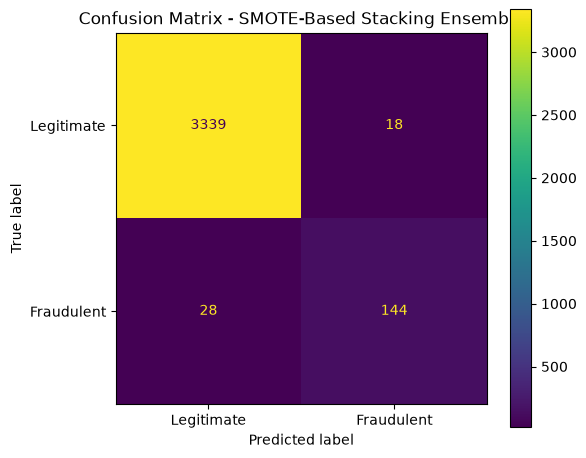

In [137]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_stack,
    display_labels=["Legitimate", "Fraudulent"]
).plot(ax=ax)

ax.set_title("Confusion Matrix - SMOTE-Based Stacking Ensemble")
plt.tight_layout()
plt.show()

In [138]:
import pandas as pd

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Linear SVM",
        "XGBoost",
        "LightGBM",
        "SMOTE-Based Stacking"
    ],
    "Accuracy": [
        0.977614,
        0.981581,
        0.984698,
        0.9745,
        0.9768,
        0.9870
    ],
    "Precision": [
        0.722488,
        0.965217,
        0.859756,
        0.7278,
        0.7296,
        0.8889
    ],
    "Recall": [
        0.877907,
        0.645349,
        0.819767,
        0.7616,
        0.8314,
        0.8372
    ],
    "F1": [
        0.792651,
        0.773519,
        0.839286,
        0.7443,
        0.7772,
        0.8623
    ],
    "ROC-AUC": [
        0.987681,
        0.987295,
        0.987018,
        0.9785,
        0.9813,
        0.9883
    ],
    "Average Precision": [
        0.887021,
        0.903597,
        0.911716,
        0.8215,
        0.8612,
        0.9155
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,0.977614,0.722488,0.877907,0.792651,0.987681,0.887021
1,Random Forest,0.981581,0.965217,0.645349,0.773519,0.987295,0.903597
2,Linear SVM,0.984698,0.859756,0.819767,0.839286,0.987018,0.911716
3,XGBoost,0.974500,0.727800,0.761600,0.744300,0.978500,0.821500
4,LightGBM,0.976800,0.729600,0.831400,0.777200,0.981300,0.861200
5,SMOTE-Based Stacking,0.987000,0.888900,0.837200,0.862300,0.988300,0.915500


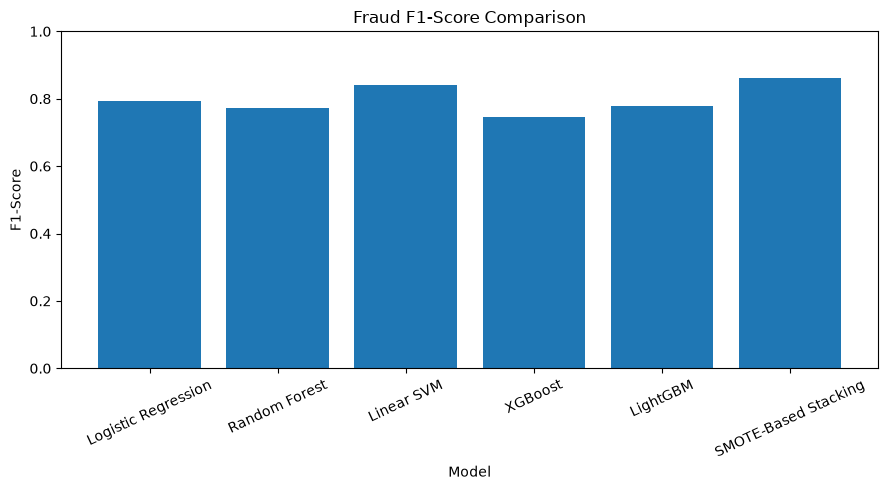

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    model_results["Model"],
    model_results["F1"]
)

plt.title("Fraud F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=25)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

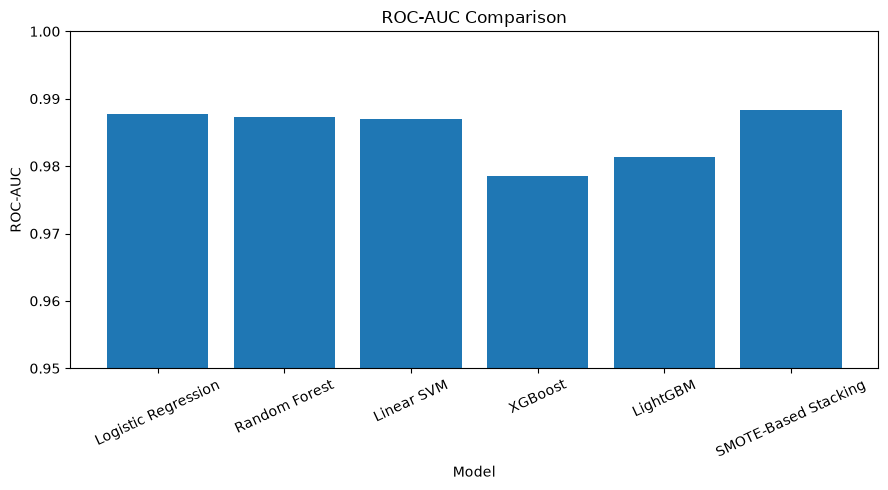

In [140]:
plt.figure(figsize=(9, 5))

plt.bar(
    model_results["Model"],
    model_results["ROC-AUC"]
)

plt.title("ROC-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=25)
plt.ylim(0.95, 1.0)

plt.tight_layout()
plt.show()

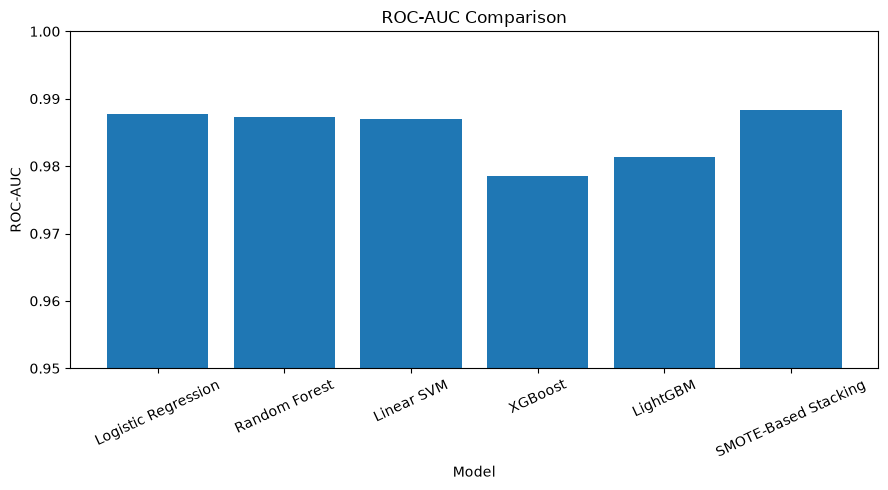

In [141]:
plt.figure(figsize=(9, 5))

plt.bar(
    model_results["Model"],
    model_results["ROC-AUC"]
)

plt.title("ROC-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=25)
plt.ylim(0.95, 1.0)

plt.tight_layout()
plt.show()

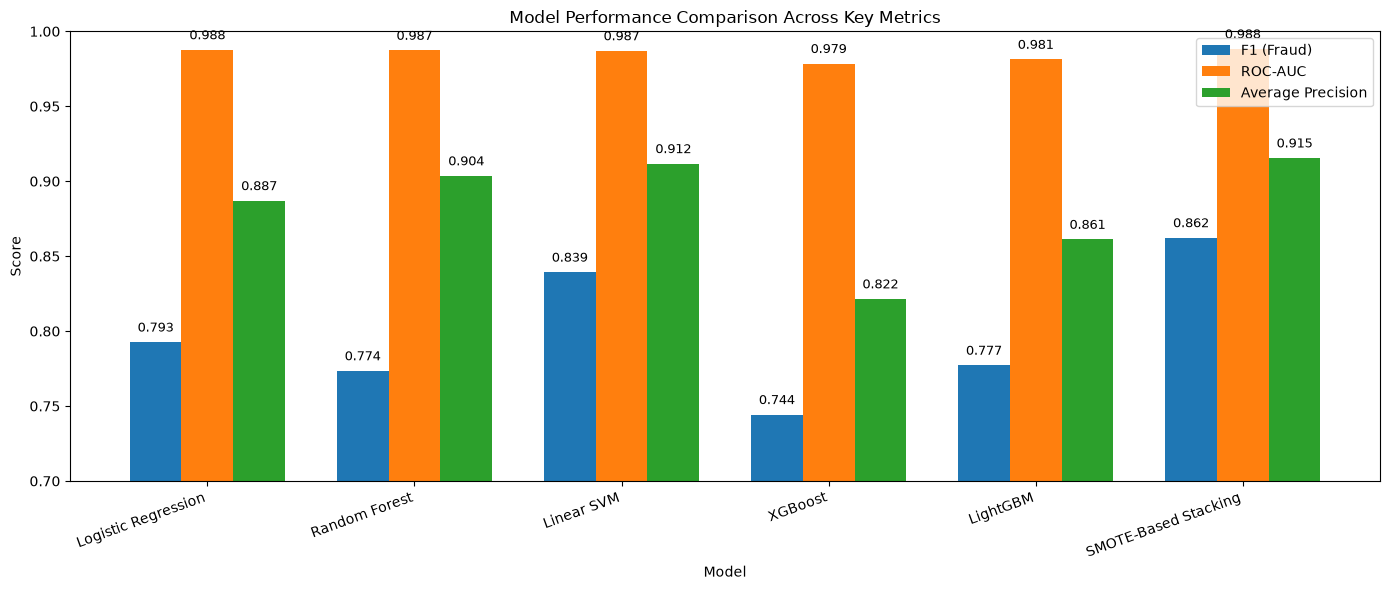

In [142]:
import matplotlib.pyplot as plt
import numpy as np

models = model_results["Model"]

f1 = model_results["F1"]
roc_auc = model_results["ROC-AUC"]
avg_precision = model_results["Average Precision"]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

bars1 = ax.bar(x - width, f1, width, label="F1 (Fraud)")
bars2 = ax.bar(x, roc_auc, width, label="ROC-AUC")
bars3 = ax.bar(x + width, avg_precision, width, label="Average Precision")

ax.set_title("Model Performance Comparison Across Key Metrics")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=20, ha="right")
ax.set_ylim(0.70, 1.0)

ax.legend()

# Add values above each bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.005,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [143]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

models_scores = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "Linear SVM": y_score_svm,
    "XGBoost": y_prob_xgb,
    "LightGBM": y_prob_lgbm,
    "SMOTE-Based Stacking": y_prob_stack_smote
}

plt.figure(figsize=(10, 7))

for name, scores in models_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc_value = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves for Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()variables_to_check = [
    "lr_model", "rf_model", "svm_model",
    "xgb_model", "lgbm_model", "meta_model",
    "X_test_hybrid", "y_test"
]

for name in variables_to_check:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

NameError: name 'y_prob_lr' is not defined

In [144]:
variables_to_check = [
    "lr_model", "rf_model", "svm_model",
    "xgb_model", "lgbm_model", "meta_model",
    "X_test_hybrid", "y_test"
]

for name in variables_to_check:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

lr_model: MISSING
rf_model: available
svm_model: available
xgb_model: available
lgbm_model: available
meta_model: available
X_test_hybrid: available
y_test: available


In [145]:
from scipy.sparse import hstack

X_train_hybrid = hstack([
    X_train_tfidf,
    X_train_cat_ohe,
    X_train_binary_sparse,
    X_train_missing_sparse
]).tocsr()

X_test_hybrid = hstack([
    X_test_tfidf,
    X_test_cat_ohe,
    X_test_binary_sparse,
    X_test_missing_sparse
]).tocsr()

print("Training:", X_train_hybrid.shape)
print("Test:", X_test_hybrid.shape)


Training: (14116, 13797)
Test: (3529, 13797)


In [146]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_smote, y_train_smote)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [147]:
y_prob_lr = lr_model.predict_proba(X_test_hybrid)[:, 1]

print("Logistic Regression probabilities generated.")
print("Number of predictions:", len(y_prob_lr))
print("Test samples:", len(y_test))
print("Match:", len(y_prob_lr) == len(y_test))

Logistic Regression probabilities generated.
Number of predictions: 3529
Test samples: 3529
Match: True


In [148]:
score_names = [
    "y_prob_lr",
    "y_prob_rf",
    "y_score_svm",
    "y_prob_xgb",
    "y_prob_lgbm",
    "y_prob_stack_smote"
]

for name in score_names:
    if name in globals():
        scores = globals()[name]
        print(f"{name}: length={len(scores)}, correct={len(scores) == len(y_test)}")
    else:
        print(f"{name}: MISSING")

y_prob_lr: length=3529, correct=True
y_prob_rf: length=3529, correct=True
y_score_svm: length=3529, correct=True
y_prob_xgb: length=3529, correct=True
y_prob_lgbm: length=3529, correct=True
y_prob_stack_smote: length=3529, correct=True


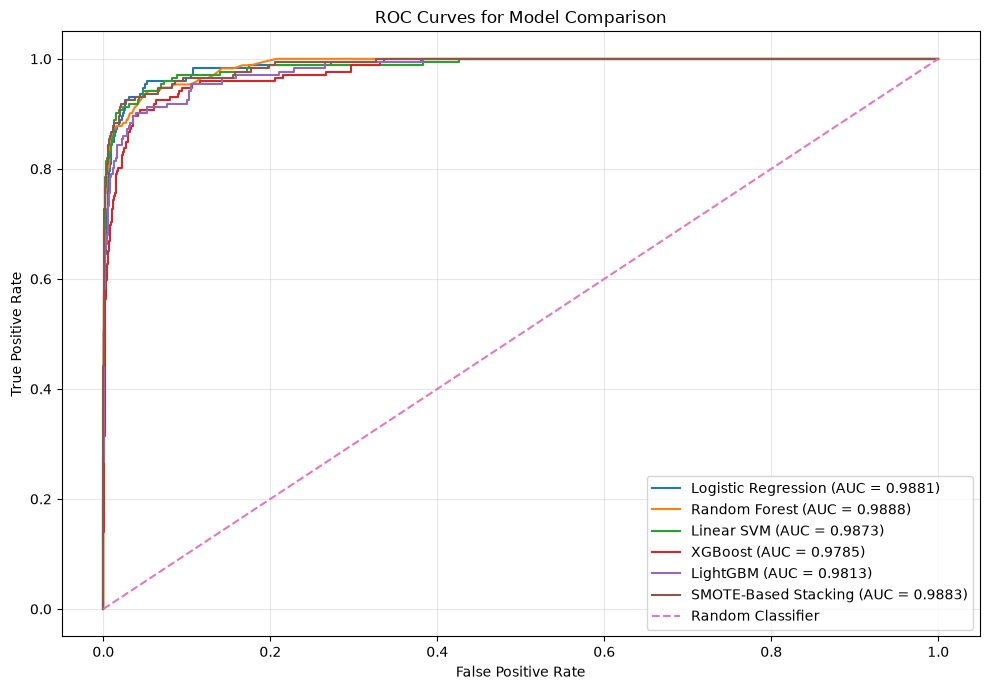

In [149]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

models_scores = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "Linear SVM": y_score_svm,
    "XGBoost": y_prob_xgb,
    "LightGBM": y_prob_lgbm,
    "SMOTE-Based Stacking": y_prob_stack_smote
}

plt.figure(figsize=(10, 7))

for name, scores in models_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc_value = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc_value:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves for Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
[name for name in [
    "lr_model",
    "rf_model",
    "svm_model",
    "xgb_model",
    "lgbm_model",
    "stack_lr",
    "stack_svm",
    "stack_lgbm",
    "meta_model",
    "X_test_hybrid",
    "y_test"
] if name in globals()]

In [150]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

current_scores = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "Linear SVM": y_score_svm,
    "XGBoost": y_prob_xgb,
    "LightGBM": y_prob_lgbm,
    "SMOTE-Based Stacking": y_prob_stack_smote
}

rows = []

for name, scores in current_scores.items():
    # Use the existing classification threshold of 0.5.
    # Linear SVM uses its decision-score threshold of 0.
    if name == "Linear SVM":
        y_pred = (scores >= 0).astype(int)
    else:
        y_pred = (scores >= 0.5).astype(int)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Fraud": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Average Precision": average_precision_score(y_test, scores)
    })

current_results = pd.DataFrame(rows)

print(current_results.round(4).to_string(index=False))

               Model  Accuracy  Precision  Recall  F1 Fraud  ROC-AUC  Average Precision
 Logistic Regression    0.9759     0.6986  0.8895    0.7826   0.9881             0.8898
       Random Forest    0.9816     0.9573  0.6512    0.7751   0.9888             0.9037
          Linear SVM    0.9841     0.8452  0.8256    0.8353   0.9873             0.9116
             XGBoost    0.9745     0.7278  0.7616    0.7443   0.9785             0.8215
            LightGBM    0.9768     0.7296  0.8314    0.7772   0.9813             0.8612
SMOTE-Based Stacking    0.9870     0.8889  0.8372    0.8623   0.9883             0.9155


In [151]:
for name in [
    "shap_values",
    "shap_importance",
    "feature_names",
    "X_shap_dense"
]:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

shap_values: MISSING
shap_importance: MISSING
feature_names: MISSING
X_shap_dense: MISSING


In [152]:
[name for name in [
    "X_train_smote",
    "y_train_smote",
    "X_train_hybrid",
    "y_train"
] if name in globals()]

['X_train_smote', 'y_train_smote', 'X_train_hybrid', 'y_train']

In [153]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_smote, y_train_smote)

y_prob_lr = lr_model.predict_proba(X_test_hybrid)[:, 1]

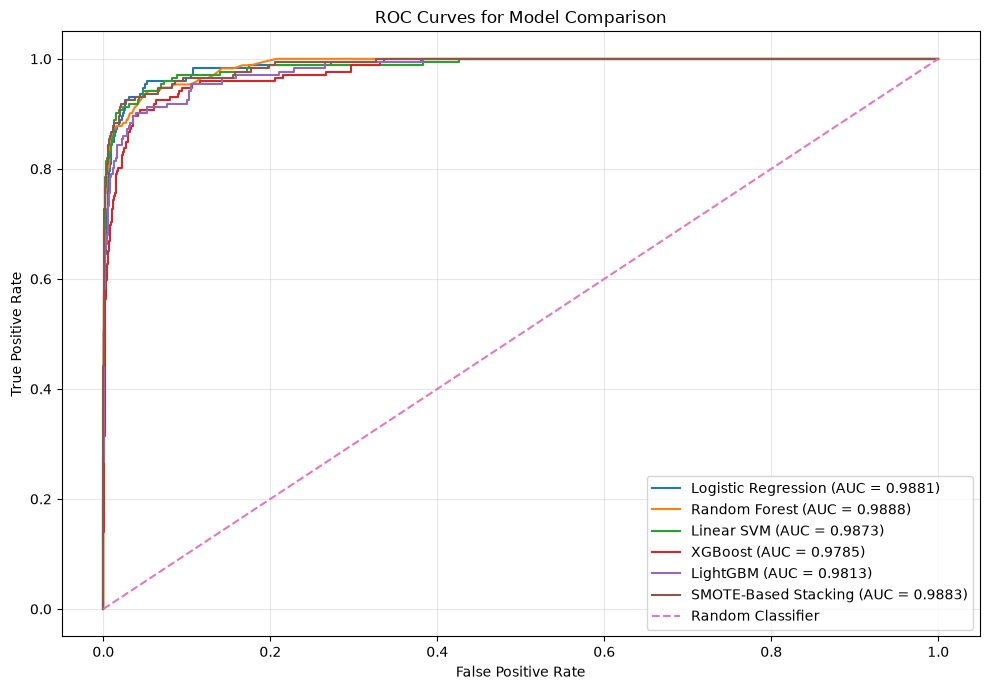

In [154]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

models_scores = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": rf_model.predict_proba(X_test_hybrid)[:, 1],
    "Linear SVM": svm_model.decision_function(X_test_hybrid),
    "XGBoost": xgb_model.predict_proba(X_test_hybrid)[:, 1],
    "LightGBM": lgbm_model.predict_proba(X_test_hybrid)[:, 1],
    "SMOTE-Based Stacking": y_prob_stack_smote
}

plt.figure(figsize=(10, 7))

for name, scores in models_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc_value = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves for Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [155]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Generate predictions and scores from the current models
predictions = {
    "Logistic Regression": (
        (y_prob_lr >= 0.5).astype(int),
        y_prob_lr
    ),
    "Random Forest": (
        rf_model.predict(X_test_hybrid),
        rf_model.predict_proba(X_test_hybrid)[:, 1]
    ),
    "Linear SVM": (
        svm_model.predict(X_test_hybrid),
        svm_model.decision_function(X_test_hybrid)
    ),
    "XGBoost": (
        xgb_model.predict(X_test_hybrid),
        xgb_model.predict_proba(X_test_hybrid)[:, 1]
    ),
    "LightGBM": (
        lgbm_model.predict(X_test_hybrid),
        lgbm_model.predict_proba(X_test_hybrid)[:, 1]
    ),
    "SMOTE-Based Stacking": (
        y_pred_stack_smote,
        y_prob_stack_smote
    )
}

results = []

for name, (pred, score) in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
        "Average Precision": average_precision_score(y_test, score)
    })

final_results = pd.DataFrame(results)

final_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,0.9759,0.6986,0.8895,0.7826,0.9881,0.8898
1,Random Forest,0.9816,0.9652,0.6453,0.7735,0.9888,0.9037
2,Linear SVM,0.9841,0.8452,0.8256,0.8353,0.9873,0.9116
3,XGBoost,0.9745,0.7278,0.7616,0.7443,0.9785,0.8215
4,LightGBM,0.9768,0.7296,0.8314,0.7772,0.9813,0.8612
5,SMOTE-Based Stacking,0.9870,0.8889,0.8372,0.8623,0.9883,0.9155


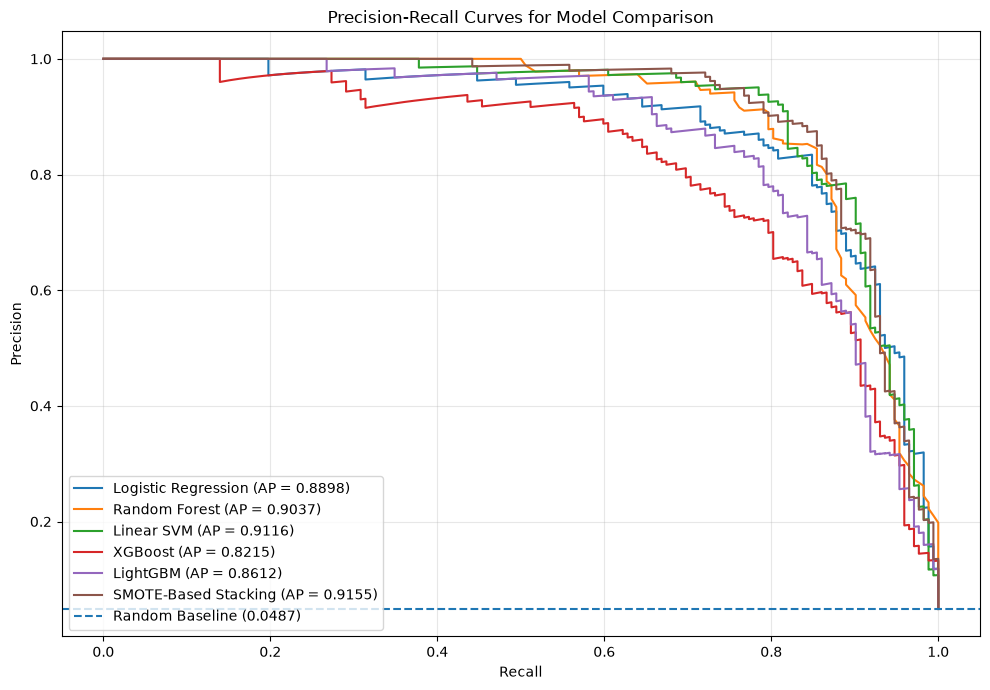

In [156]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

models_scores = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": rf_model.predict_proba(X_test_hybrid)[:, 1],
    "Linear SVM": svm_model.decision_function(X_test_hybrid),
    "XGBoost": xgb_model.predict_proba(X_test_hybrid)[:, 1],
    "LightGBM": lgbm_model.predict_proba(X_test_hybrid)[:, 1],
    "SMOTE-Based Stacking": y_prob_stack_smote
}

plt.figure(figsize=(10, 7))

for name, scores in models_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.4f})"
    )

# Random baseline = proportion of fraudulent samples
fraud_rate = y_test.mean()

plt.axhline(
    y=fraud_rate,
    linestyle="--",
    label=f"Random Baseline ({fraud_rate:.4f})"
)

plt.title("Precision-Recall Curves for Model Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

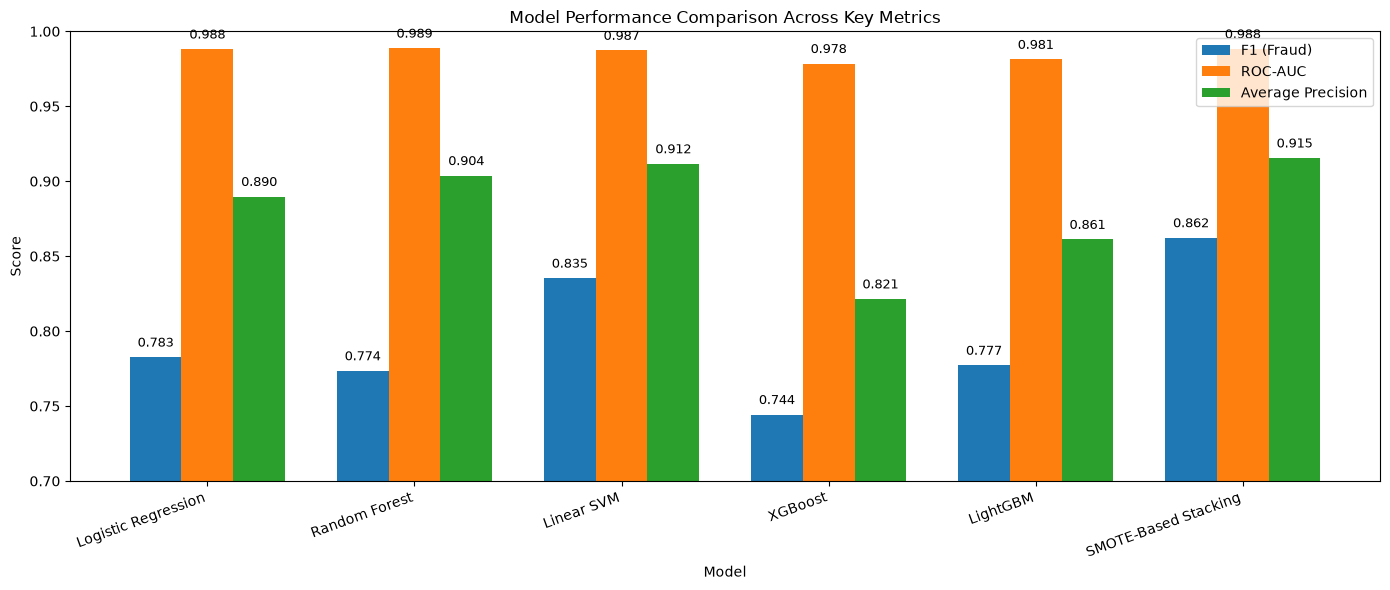

In [157]:
import matplotlib.pyplot as plt
import numpy as np

models = final_results["Model"]

f1 = final_results["F1"]
roc_auc = final_results["ROC-AUC"]
avg_precision = final_results["Average Precision"]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

bars1 = ax.bar(x - width, f1, width, label="F1 (Fraud)")
bars2 = ax.bar(x, roc_auc, width, label="ROC-AUC")
bars3 = ax.bar(x + width, avg_precision, width, label="Average Precision")

ax.set_title("Model Performance Comparison Across Key Metrics")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=20, ha="right")
ax.set_ylim(0.70, 1.0)

ax.legend()

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.005,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [158]:
svm_f1 = final_results.loc[
    final_results["Model"] == "Linear SVM", "F1"
].iloc[0]

stack_f1 = final_results.loc[
    final_results["Model"] == "SMOTE-Based Stacking", "F1"
].iloc[0]

improvement = (stack_f1 - svm_f1) * 100

print(f"Linear SVM F1: {svm_f1:.4f}")
print(f"Stacking F1:   {stack_f1:.4f}")
print(f"Improvement:   {improvement:.2f} percentage points")

Linear SVM F1: 0.8353
Stacking F1:   0.8623
Improvement:   2.70 percentage points


In [159]:
print("=== FINAL PIPELINE SANITY CHECK ===\n")

print("Test set:")
print("X_test_hybrid:", X_test_hybrid.shape)
print("y_test:", y_test.shape)
print("Fraud cases in test:", y_test.sum())

print("\nSMOTE training set:")
print("X_train_smote:", X_train_smote.shape)
print("y_train_smote:", y_train_smote.shape)
print("Class distribution:")
print(y_train_smote.value_counts().sort_index())

print("\nStacking predictions:")
print("Stacking predictions:", y_pred_stack_smote.shape)
print("Stacking probabilities:", y_prob_stack_smote.shape)

print("\nFinal model results:")
print(final_results.round(4).to_string(index=False))

=== FINAL PIPELINE SANITY CHECK ===

Test set:
X_test_hybrid: (3529, 13797)
y_test: (3529,)
Fraud cases in test: 172

SMOTE training set:
X_train_smote: (26860, 13797)
y_train_smote: (26860,)
Class distribution:
fraudulent
0    13430
1    13430
Name: count, dtype: int64

Stacking predictions:
Stacking predictions: (3529,)
Stacking probabilities: (3529,)

Final model results:
               Model  Accuracy  Precision  Recall     F1  ROC-AUC  Average Precision
 Logistic Regression    0.9759     0.6986  0.8895 0.7826   0.9881             0.8898
       Random Forest    0.9816     0.9652  0.6453 0.7735   0.9888             0.9037
          Linear SVM    0.9841     0.8452  0.8256 0.8353   0.9873             0.9116
             XGBoost    0.9745     0.7278  0.7616 0.7443   0.9785             0.8215
            LightGBM    0.9768     0.7296  0.8314 0.7772   0.9813             0.8612
SMOTE-Based Stacking    0.9870     0.8889  0.8372 0.8623   0.9883             0.9155


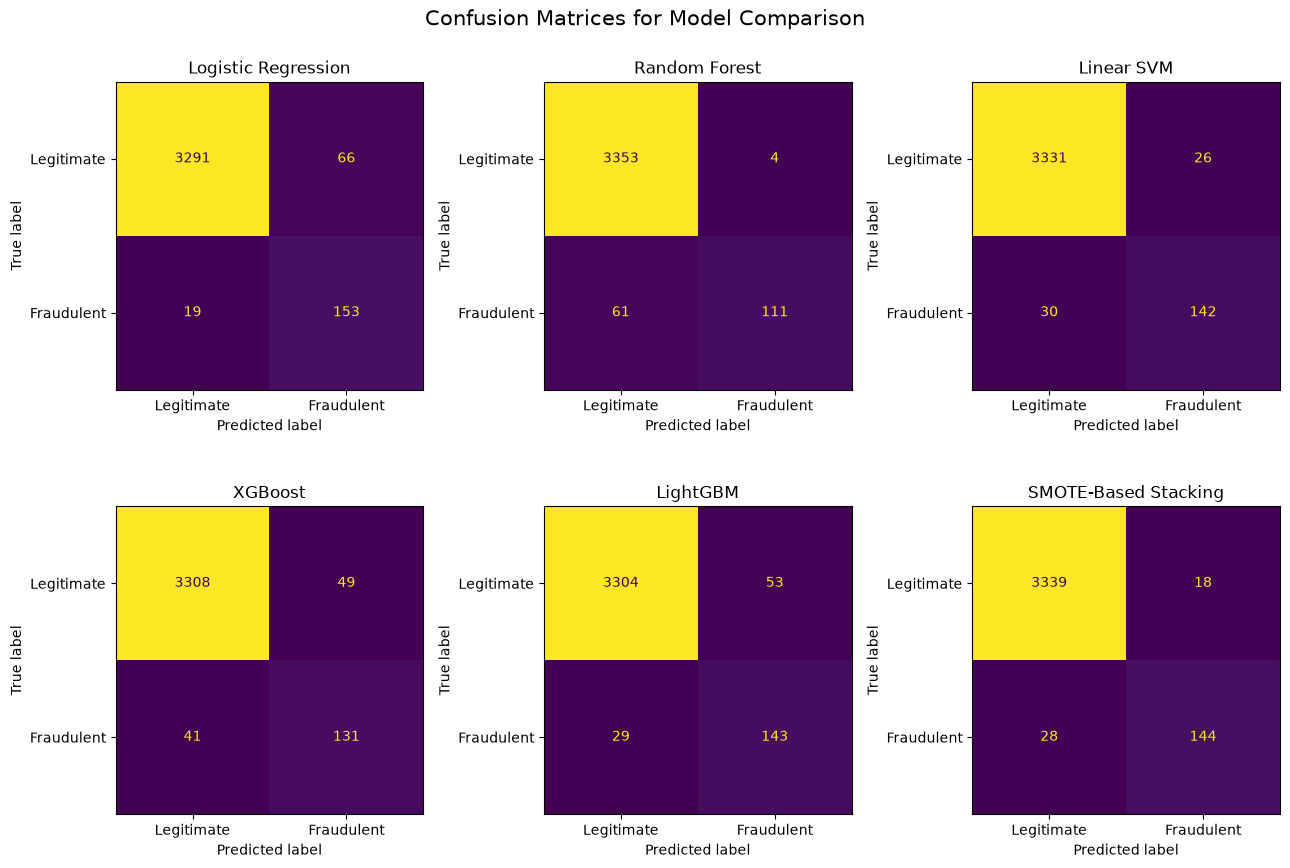

In [160]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
axes = axes.ravel()

for ax, (name, (pred, score)) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraudulent"]
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices for Model Comparison", fontsize=15)
plt.tight_layout()
plt.show()

In [161]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [163]:
print("TF-IDF features:", X_train_tfidf.shape[1])
print("Categorical OHE features:", X_train_cat_ohe.shape[1])
print("Binary features:", X_train_binary_sparse.shape[1])
print("Missingness features:", X_train_missing_sparse.shape[1])

print("\nTotal hybrid features:", X_train_hybrid.shape[1])

print("\nCurrent OHE categories:")
print("Number of categorical columns:", len(ohe.categories_))
print("Total categories:", sum(len(c) for c in ohe.categories_))

TF-IDF features: 10000
Categorical OHE features: 3791
Binary features: 3
Missingness features: 3

Total hybrid features: 13797

Current OHE categories:
Number of categorical columns: 7
Total categories: 4136


In [164]:
[name for name in globals()
 if any(word in name.lower() for word in [
     "feature_names",
     "tfidf_names",
     "cat_names",
     "feature_name"
 ])]

[]

In [165]:
[name for name, obj in globals().items()
 if "OneHotEncoder" in str(type(obj))]

['ohe', 'encoder', 'ohe_location', 'ohe_split_location', 'ohe_final']

In [166]:
for name in ["ohe", "encoder", "ohe_location", "ohe_split_location", "ohe_final"]:
    obj = globals().get(name)
    if obj is not None and hasattr(obj, "categories_"):
        print(f"{name}:")
        print("  number of categorical columns:", len(obj.categories_))
        print("  total categories:", sum(len(c) for c in obj.categories_))
        print("  feature output shape:", len(obj.get_feature_names_out()))
        print()

ohe:
  number of categorical columns: 7
  total categories: 4136
  feature output shape: 4136

encoder:
  number of categorical columns: 7
  total categories: 143
  feature output shape: 143

ohe_location:
  number of categorical columns: 1
  total categories: 2761
  feature output shape: 2761

ohe_split_location:
  number of categorical columns: 3
  total categories: 2416
  feature output shape: 2416

ohe_final:
  number of categorical columns: 9
  total categories: 3791
  feature output shape: 3791



In [167]:
tfidf_names = tfidf.get_feature_names_out()
ohe_names = ohe_final.get_feature_names_out()

binary_names = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

missing_names = [
    "company_profile_missing",
    "employment_type_missing",
    "required_experience_missing"
]

feature_names = np.concatenate([
    tfidf_names,
    ohe_names,
    binary_names,
    missing_names
])

print("TF-IDF features:", len(tfidf_names))
print("OHE features:", len(ohe_names))
print("Binary features:", len(binary_names))
print("Missingness features:", len(missing_names))
print("Total feature names:", len(feature_names))
print("Actual hybrid features:", X_test_hybrid.shape[1])
print("Match:", len(feature_names) == X_test_hybrid.shape[1])

TF-IDF features: 10000
OHE features: 3791
Binary features: 3
Missingness features: 3
Total feature names: 13797
Actual hybrid features: 13797
Match: True


In [168]:
import shap

# Use a fixed sample from the untouched test set
X_shap = X_test_hybrid[:200]

# Convert only the small sample to dense format
X_shap_dense = X_shap.toarray()

print("SHAP sample shape:", X_shap_dense.shape)
print("Feature count:", X_shap_dense.shape[1])
print("Feature-name count:", len(feature_names))
print("Match:", X_shap_dense.shape[1] == len(feature_names))

SHAP sample shape: (200, 13797)
Feature count: 13797
Feature-name count: 13797
Match: True


In [169]:
# Create SHAP TreeExplainer for the LightGBM component
explainer = shap.TreeExplainer(lgbm_model)

# Calculate SHAP values for the 200 test samples
shap_values = explainer.shap_values(X_shap_dense)

print("SHAP values type:", type(shap_values))
print("SHAP values shape:", np.array(shap_values).shape)

SHAP values type: <class 'numpy.ndarray'>
SHAP values shape: (200, 13797)


/home/maryam/EMSCAD_Project/.venv/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [170]:
print("SHAP values shape:", shap_values.shape)
print("Minimum SHAP value:", shap_values.min())
print("Maximum SHAP value:", shap_values.max())
print("Any NaN values:", np.isnan(shap_values).any())
print("Any infinite values:", np.isinf(shap_values).any())

SHAP values shape: (200, 13797)
Minimum SHAP value: -1.106808438695893
Maximum SHAP value: 1.4703034854491388
Any NaN values: False
Any infinite values: False


In [171]:
# Calculate mean absolute SHAP importance for every feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Create a table of the most important features
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

print(shap_importance.head(20).to_string(index=False))

                                     feature  mean_abs_shap
                     company_profile_missing       0.762571
                            has_company_logo       0.366360
                                  country_US       0.232180
required_education_High School or equivalent       0.207173
                                     growing       0.168799
                              are encouraged       0.166260
                               has_questions       0.158151
                                      of our       0.147408
                                        earn       0.136568
                                         and       0.130286
        required_education_Bachelor's Degree       0.127813
                                         000       0.123862
                                    computer       0.114051
                                  data entry       0.113215
                                         our       0.112813
                                        

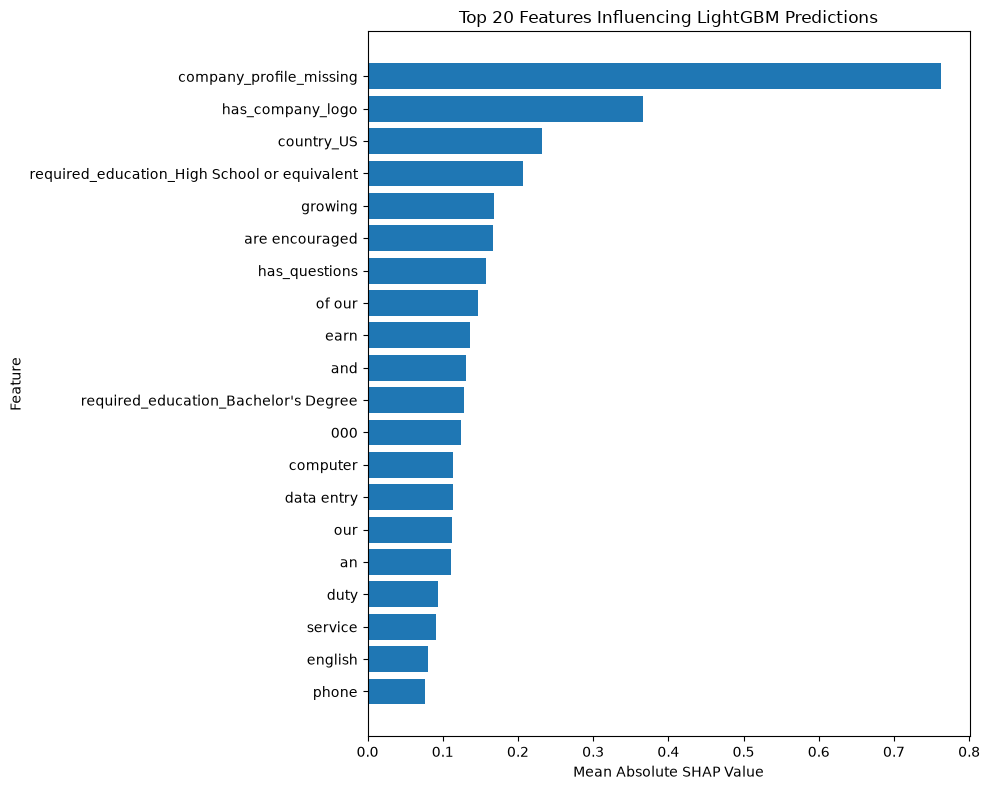

In [172]:
import matplotlib.pyplot as plt

# Select the 20 most important features
top20 = shap_importance.head(20).sort_values(
    "mean_abs_shap",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["feature"],
    top20["mean_abs_shap"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing LightGBM Predictions")

plt.tight_layout()
plt.show()

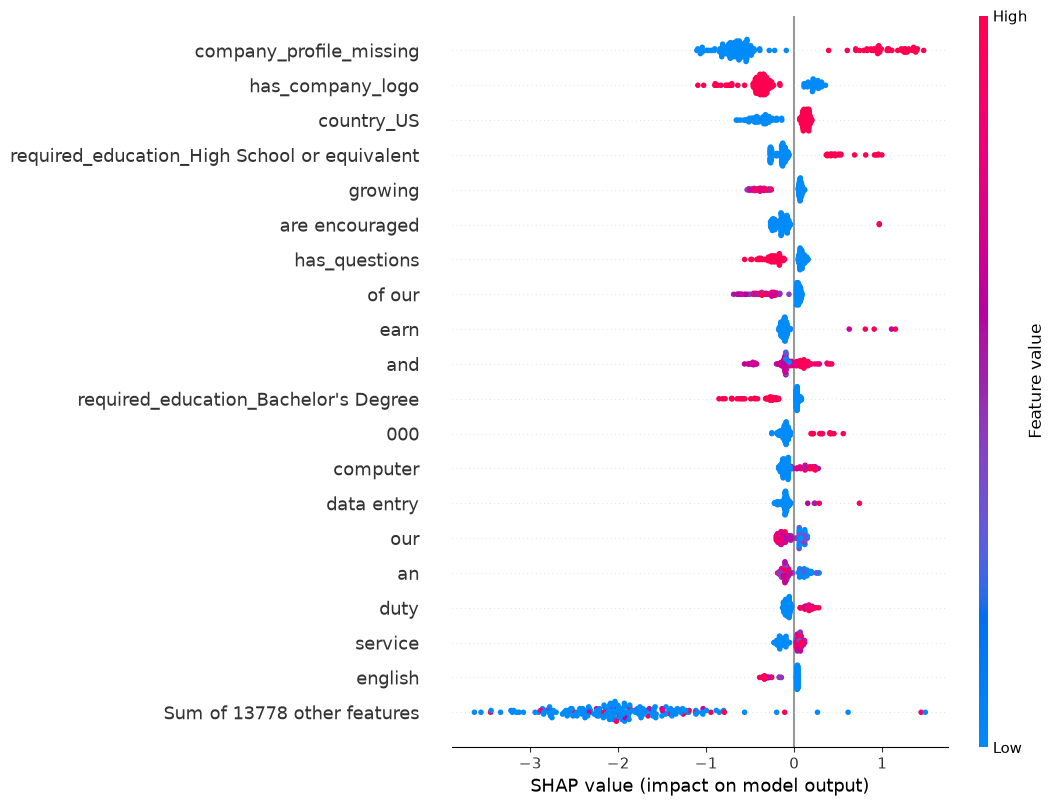

In [173]:
# Create SHAP Explanation object
shap_explanation = shap.Explanation(
    values=shap_values,
    data=X_shap_dense,
    feature_names=feature_names
)

# SHAP beeswarm plot for the top 20 features
shap.plots.beeswarm(
    shap_explanation,
    max_display=20,
    show=True
)

In [174]:
top_features = shap_importance.head(20)["feature"].tolist()

shap_direction = pd.DataFrame({
    "feature": feature_names,
    "mean_shap": shap_values.mean(axis=0),
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

shap_direction = (
    shap_direction[shap_direction["feature"].isin(top_features)]
    .sort_values("mean_shap", ascending=False)
    .reset_index(drop=True)
)

print(shap_direction.to_string(index=False))

                                     feature  mean_shap  mean_abs_shap
                                     english  -0.021469       0.079917
                                       phone  -0.022559       0.075930
                                     service  -0.025617       0.091572
                                          an  -0.031404       0.111049
                                        duty  -0.033454       0.093843
                                         our  -0.045690       0.112813
                                         and  -0.048473       0.130286
                                    computer  -0.060342       0.114051
                               has_questions  -0.064410       0.158151
required_education_High School or equivalent  -0.065078       0.207173
                                  country_US  -0.068523       0.232180
                                     growing  -0.069496       0.168799
        required_education_Bachelor's Degree  -0.074581       0.127813
      

In [175]:
top_features = shap_importance.head(20)["feature"].tolist()

shap_direction = pd.DataFrame({
    "feature": feature_names,
    "mean_shap": shap_values.mean(axis=0),
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

shap_direction = (
    shap_direction[shap_direction["feature"].isin(top_features)]
    .sort_values("mean_shap", ascending=False)
    .reset_index(drop=True)
)

print(shap_direction.to_string(index=False))

                                     feature  mean_shap  mean_abs_shap
                                     english  -0.021469       0.079917
                                       phone  -0.022559       0.075930
                                     service  -0.025617       0.091572
                                          an  -0.031404       0.111049
                                        duty  -0.033454       0.093843
                                         our  -0.045690       0.112813
                                         and  -0.048473       0.130286
                                    computer  -0.060342       0.114051
                               has_questions  -0.064410       0.158151
required_education_High School or equivalent  -0.065078       0.207173
                                  country_US  -0.068523       0.232180
                                     growing  -0.069496       0.168799
        required_education_Bachelor's Degree  -0.074581       0.127813
      

In [176]:
print("Model classes:", lgbm_model.classes_)
print("Model output type:", explainer.model.model_output)

# Compare SHAP reconstruction with the model's raw predictions
raw_predictions = lgbm_model.booster_.predict(
    X_shap_dense,
    raw_score=True
)

base_value = np.asarray(explainer.expected_value).reshape(-1)[0]
reconstructed = base_value + shap_values.sum(axis=1)

print("First 5 raw predictions:", raw_predictions[:5])
print("First 5 SHAP reconstructions:", reconstructed[:5])
print(
    "Maximum reconstruction error:",
    np.max(np.abs(raw_predictions - reconstructed))
)

Model classes: [0 1]
Model output type: raw
First 5 raw predictions: [-3.13699094 -2.80401443 -3.47249022 -5.16626686 -4.95812606]
First 5 SHAP reconstructions: [-3.13699094 -2.80401443 -3.47249022 -5.16626686 -4.95812606]
Maximum reconstruction error: 4.440892098500626e-15


In [177]:
features_to_check = [
    "company_profile_missing",
    "has_company_logo",
    "country_US",
    "has_questions"
]

for feature in features_to_check:
    idx = np.where(feature_names == feature)[0][0]

    values = X_shap_dense[:, idx]
    contributions = shap_values[:, idx]

    print(f"\nFeature: {feature}")
    print("Feature value counts:")
    print(pd.Series(values).value_counts().sort_index().to_dict())
    print("Mean SHAP when value = 0:",
          contributions[values == 0].mean()
          if np.any(values == 0) else "No samples")
    print("Mean SHAP when value = 1:",
          contributions[values == 1].mean()
          if np.any(values == 1) else "No samples")


Feature: company_profile_missing
Feature value counts:
{0.0: 153, 1.0: 47}
Mean SHAP when value = 0: -0.6688799881050025
Mean SHAP when value = 1: 1.0675645284755468

Feature: has_company_logo
Feature value counts:
{0.0: 45, 1.0: 155}
Mean SHAP when value = 0: 0.22341279709578776
Mean SHAP when value = 1: -0.4078603988027917

Feature: country_US
Feature value counts:
{0.0: 78, 1.0: 122}
Mean SHAP when value = 0: -0.38551688425971714
Mean SHAP when value = 1: 0.13414535392522375

Feature: has_questions
Feature value counts:
{0.0: 106, 1.0: 94}
Mean SHAP when value = 0: 0.08843485324471805
Mean SHAP when value = 1: -0.23676728743142128


In [178]:
text_features_to_check = [
    "growing",
    "are encouraged",
    "earn",
    "computer",
    "data entry",
    "of our"
]

for feature in text_features_to_check:
    idx = np.where(feature_names == feature)[0][0]
    values = X_shap_dense[:, idx]
    contributions = shap_values[:, idx]

    present = values > 0
    absent = ~present

    print(f"\nFeature: {feature}")
    print("Present in samples:", int(present.sum()))
    print("Mean SHAP when present:",
          round(contributions[present].mean(), 4)
          if present.any() else "No samples")
    print("Mean SHAP when absent:",
          round(contributions[absent].mean(), 4)
          if absent.any() else "No samples")


Feature: growing
Present in samples: 61
Mean SHAP when present: -0.3893
Mean SHAP when absent: 0.0708

Feature: are encouraged
Present in samples: 2
Mean SHAP when present: 0.9662
Mean SHAP when absent: -0.1582

Feature: earn
Present in samples: 5
Mean SHAP when present: 0.919
Mean SHAP when absent: -0.1165

Feature: computer
Present in samples: 38
Mean SHAP when present: 0.1399
Mean SHAP when absent: -0.1073

Feature: data entry
Present in samples: 5
Mean SHAP when present: 0.3283
Mean SHAP when absent: -0.1077

Feature: of our
Present in samples: 66
Mean SHAP when present: -0.3436
Mean SHAP when absent: 0.0498
